<style>
/* Deck-only CSS. Deliberately almost empty.

   Everything that used to live here -- heading sizes in px, a smaller table font, a cap on
   figure height, tighter list and paragraph margins -- restyled the slide away from what
   the notebook shows, which is precisely what made the notebook a poor preview of the
   deck. With those gone, a slide renders with Jupyter's own typography, so what you see in
   the notebook is what the slide gets, and figures are governed by the dpi convention in
   the setup cell instead (1 inch = 100 slide px; a figure fills the width at 12.0in).

   Put an override back here if a slide genuinely needs one -- but expect it to make the
   notebook preview wrong by exactly that much.

   The two rules below are the exceptions, and both are deliberate.

   The first is where the slide ends -- no notebook equivalent, and not expressible in
   reveal's config. It sits on reveal's own .slides element, whose box IS the slide area,
   and it is an outline rather than a border so it takes no part in layout.

   The second centres figures. A figure narrower than the slide is left-aligned by
   Jupyter's output area, which looks like a mistake on a projector. This is scoped to
   images inside an output area so it cannot catch anything else, and it changes placement
   only -- never size -- so the notebook stays an honest preview of how much room a figure
   takes. Centre it in the notebook too and the two match exactly. */
.reveal .slides        { outline: 1px solid #c3c9d4; }

/* MathJax 2 drops a .MathJax_Preview placeholder beside every equation and is supposed to
   hide it once it has typeset the real thing. When that step does not land, the equation
   appears twice -- once as the placeholder, once as the rendered form. This deck carries
   208 of them, so the failure mode is worth closing off. The cost: if MathJax never loads
   at all, an equation renders as nothing rather than as its LaTeX source. */
.MathJax_Preview       { display: none !important; }
.reveal .jp-OutputArea-output img { display: block; margin-left: auto; margin-right: auto; }

/* Printed output at the same size and rhythm as prose: Jupyter renders it at 0.95em with
   a tighter line-height, which reads as a different medium on a slide. 1em inherits the
   20px content base, so this tracks the prose rather than pinning a number.

   The size is taken from --jp-content-font-size1, the variable the prose itself resolves
   to, so it tracks the prose rather than pinning a number.

   The selector shape is not arbitrary. nbconvert's slides template ships
   `.reveal div.jp-OutputArea-output > pre { font-size: var(--jp-code-font-size) }`, which
   at (0,2,2) outranks the obvious `.reveal .jp-OutputArea-output pre` at (0,2,1) -- that
   one matches the element and silently loses on font-size alone. Matching the template's
   shape ties the specificity, and this sheet comes later, so it wins.

   The font FAMILY stays monospace on purpose. Eight of the seventeen printed blocks in
   this lesson are columns held together by spaces -- "nodes  : 10 / edges  : 16", the
   version banner, the per-mode percentages -- and a proportional font collapses every one
   of them. Matching size and leading gets the two media to sit together; matching the
   family would cost the alignment those blocks are built on. */
.reveal div.jp-OutputArea-output > pre { font-size: var(--jp-content-font-size1);
                                         line-height: 1.3; }

/* Side-by-side markdown. Tag two consecutive markdown cells `side-by-side` and they share one
   row, half the slide width each; everything before and after them -- the heading, the figure --
   stays full width, so the slide itself is still one column. nbconvert writes each cell tag as a
   class, celltag_<tag>, but on the cell's inner rendered-markdown div, so :has() reaches up to the
   cell. The notebook shows the two cells one above the other. */
.reveal .jp-MarkdownCell:has(.celltag_side-by-side) {
    float: left; width: 50%; box-sizing: border-box; padding-right: 1.5em; }
.reveal .jp-MarkdownCell:has(.celltag_side-by-side) + .jp-Cell:not(:has(.celltag_side-by-side)) {
    clear: both; }
.reveal .slides > section > section::after { content: ""; display: block; clear: both; }
</style>

<script type="text/x-mathjax-config">
// nbconvert's template sets CommonHTML.linebreaks.automatic = true. MathJax then breaks math to
// fit its container, and inside a table cell the container has no settled width yet: every
// table with math in it collapses into narrow, over-tall columns with the equations broken at
// each operator. Switching it off costs nothing here -- no equation in this deck is wider
// than the slide. This belongs in make_slides.py; it lives here until the build carries it.
MathJax.Hub.Config({ CommonHTML: { linebreaks: { automatic: false } } });
</script>


# Graph Spectral Analysis

### What the eigenvectors of a graph tell you about data measured on it

| Part | Question |
|---|---|
| **1. Graphs and the operator** | What is a graph, which matrix do we decompose, what do its eigenvectors mean? |
| **2. Springs and masses** | The same eigenproblem you already know, in 1-D |
| **3. Temperature sensors** | A worked example, end to end |
| **4. Elsewhere** | Transportation networks, image compression, clustering |

One idea, up front:

> A graph builds **its own basis**. Sort that basis from *smoothest* to *roughest* and you get a
> usable notion of **frequency** for data with no grid, no time axis, and no natural ordering.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

SEED = 7
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    # 100 dpi makes the notebook an honest preview of the deck: one inch of figure is 100
    # slide pixels, so a figure fills the slide's width at 12.0in (R4.1, R4.2).
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 12,             # R5.3 minimum; 14 crowds 3-panel figures at 12 in
    "axes.titlesize": 12,
})
# Save exactly figsize x dpi. The default 'tight' bbox crops by a varying amount, which
# would make every figure a different size from the one written here (R5.1).
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}

import scipy, matplotlib
for nm, m in [("numpy", np), ("scipy", scipy), ("networkx", nx), ("matplotlib", matplotlib)]:
    print(f"{nm:<11} {m.__version__}")

numpy       2.5.3
scipy       1.18.1
networkx    3.6.1
matplotlib  3.11.1


In [2]:
# ---- two plotting helpers, used by every figure below -------------------------------

def show_graph(ax, node_color="#dbeafe", widths=2.0, title="", cmap=None,
               vmin=None, vmax=None, pos=None, node_size=620):
    "Draw the running example. Returns the node collection, for colorbars."
    p = POS if pos is None else pos
    nx.draw_networkx_edges(G, p, ax=ax, width=widths, edge_color="#7b8794")
    coll = nx.draw_networkx_nodes(G, p, ax=ax, nodelist=NODES, node_color=node_color,
                                  cmap=cmap, vmin=vmin, vmax=vmax, node_size=node_size,
                                  edgecolors="#334155", linewidths=1.3)
    nx.draw_networkx_labels(G, p, ax=ax, font_size=11, font_color="#0f172a")
    ax.set_title(title)
    ax.set_axis_off()
    ax.set_aspect("equal")
    # Node markers are sized in points^2, but the axes autoscale to the node CENTRES, so
    # the outermost markers hang over the data limits and get clipped at the edge of the
    # axes. Pad the limits instead of shrinking the nodes; y needs more because these
    # layouts are wide and short.
    ax.margins(x=0.07, y=0.18)
    return coll


def show_matrix(ax, M, title, fmt="{:.0f}", fontsize=10, blank_zeros=True):
    "Heatmap of a small matrix with the numbers written in."
    lim = np.abs(M).max()
    signed = M.min() < -1e-12                      # diverging map only when signs differ
    im = ax.imshow(M, cmap="RdBu_r" if signed else "Blues",
                   vmin=-lim if signed else 0, vmax=lim)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if blank_zeros and abs(v) < 1e-12:
                continue
            strong = abs(v) > 0.6 * lim if signed else v > 0.6 * lim
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                    color="white" if strong else "#0f172a")
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))
    ax.set_xlabel("node $j$")
    ax.set_ylabel("node $i$")
    ax.set_title(title)
    ax.grid(False)
    return im

## 1.1  Graph Definition

$$\LARGE G=(V,E) \qquad |V| = n \text{ nodes} \qquad E \subseteq \big\{\{i,j\} : i \neq j\big\} \text{ edges}$$

- **Undirected**: $\{i,j\}$ and $\{j,i\}$ are one edge, so none of the 16 edges below carries a direction.
- **Simple**: no self-loops, and no pair joined twice.
- **Connected**: one component, so every node is reachable from every other.
- **Signal**: not part of $G$. The graph fixes only *which nodes are related*; the numbers
  measured at those nodes are a separate object laid on top of it, and they arrive in §1.4.
- Index $i$ or $j$ *always* means $i$-th or $j$-th node


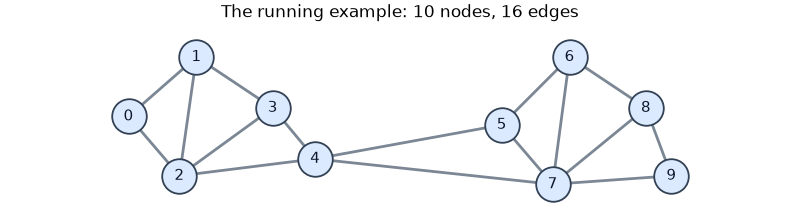

nodes                : 10
edges                : 16
connected components : 1


In [3]:
NODES = list(range(10))
EDGES = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 3), (3, 4), (2, 4),   # left group
         (5, 6), (5, 7), (6, 7), (6, 8), (7, 8), (8, 9), (7, 9),   # right group
         (4, 5), (4, 7)]                                           # the two links between

POS = {0: (0.0, 1.0), 1: (0.8, 1.7), 2: (0.6, 0.3), 3: (1.7, 1.1), 4: (2.2, 0.5),
       5: (4.4, 0.9), 6: (5.2, 1.7), 7: (5.0, 0.2), 8: (6.1, 1.1), 9: (6.4, 0.3)}

G = nx.Graph()
G.add_nodes_from(NODES)      # fixed node ordering: row i of every matrix is node i
G.add_edges_from(EDGES)
n = G.number_of_nodes()

fig, ax = plt.subplots(figsize=(8, 2.2))
show_graph(ax, title="The running example: 10 nodes, 16 edges")
plt.show()

print(f"nodes                : {n}")
print(f"edges                : {G.number_of_edges()}")
print(f"connected components : {nx.number_connected_components(G)}")

Two dense groups, joined by exactly **two** edges: 4&ndash;5 and 4&ndash;7. Everything in §1.2&ndash;§1.5 is computed from the edge list alone. The drawing is only a drawing.

- The edge list is a **modelling choice**, not a measurement. Someone decided what *related* means.
- The nodes also carry **positions**. Those are ignored until §1.7.


## 1.2  The adjacency matrix $A$

$A$ is the edge list rewritten as an $n \times n$ matrix. 

$$A_{ij} = \begin{cases} 1 & \{i,j\} \in E \\[2pt] 0 & \text{otherwise} \end{cases}
\qquad\qquad A = A^\top, \qquad A_{ii} = 0$$

- **Symmetric**, because the graph is undirected. That is what earns us a real orthonormal eigenbasis later.
- **Sparse**: Only entries in $(i,j)$ with edges

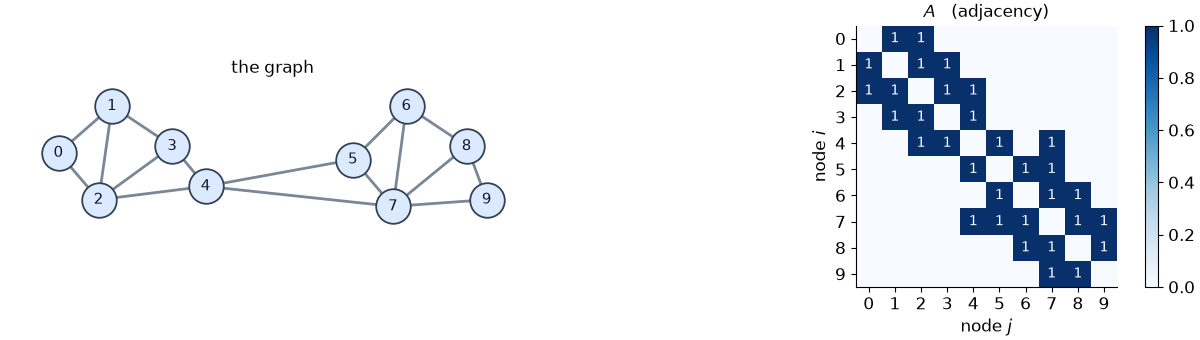

In [4]:
A = nx.to_numpy_array(G, nodelist=NODES)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 1.05]})
show_graph(axes[0], title="the graph")
im = show_matrix(axes[1], A, "$A$   (adjacency)")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.show()


In [5]:
print("symmetric:", np.allclose(A, A.T),
      "| zero diagonal:", np.allclose(np.diag(A), 0),
      "| values:", np.unique(A))

symmetric: True | zero diagonal: True | values: [0. 1.]


## 1.3  Degree $D$, and the Laplacian $L$

$$d_i = \textstyle\sum_j A_{ij}\;\;\text{(row sum)}, \qquad D = \operatorname{diag}(d_1,\dots,d_n)$$

$$\boxed{\,L = D - A\,} \qquad L_{ij} = \begin{cases} d_i & i = j \\ -1 & \{i,j\} \in E \\ 0 & \text{otherwise}\end{cases}$$


| Property | Reason |
|---|---|
| Symmetric, $L = L^\top$ | $A$ and $D$ both are |
| every row sums to $0$, i.e. $L\mathbf{1} = \mathbf{0}$ | $d_i$ = \textstyle\sum_j A_{ij} |


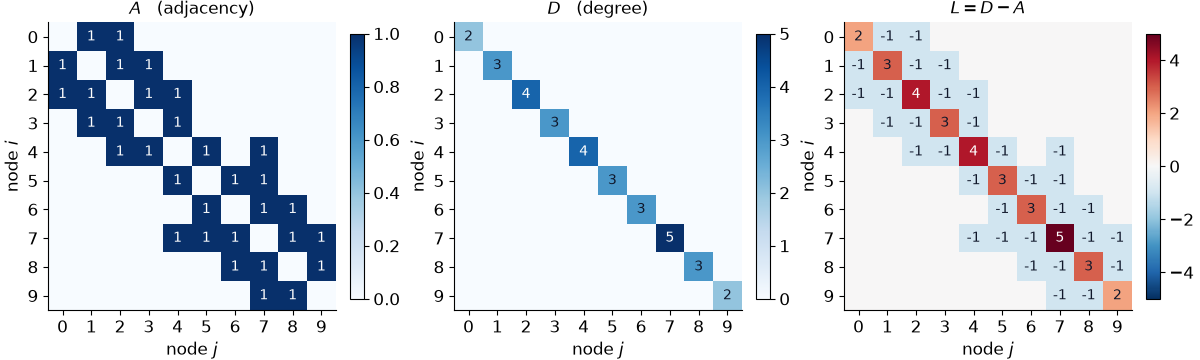

In [6]:
d = A.sum(axis=1)     # degree vector
D = np.diag(d)        # degree matrix
L = D - A             # combinatorial graph Laplacian

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, M, t in zip(axes, [A, D, L], ["$A$   (adjacency)", "$D$   (degree)", "$L = D - A$"]):
    im = show_matrix(ax, M, t)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()


In [7]:
print("L symmetric :", np.allclose(L, L.T))
print("L @ 1 == 0  :", np.allclose(L @ np.ones(n), 0))

L symmetric : True
L @ 1 == 0  : True


## 1.3  $L$ is a difference operator

For any vector $q \in \mathbb{R}^n$,

$$(Lq)_i \;=\; d_i\,q_i - \!\!\sum_{j \sim i}\! q_j \;=\; \sum_{j \sim i} (q_i - q_j)$$

- Entry $i$ of $Lq$ = **how far node $i$ sits from its own neighbours**.
- A constant vector goes to zero.
- This is the graph version of $-\nabla^2$, which is where the name *Laplacian* comes from.

## 1.4  A signal on a graph

A **graph signal** is one number per node:

$$x \in \mathbb{R}^n, \qquad x_i = \text{the value measured at node } i$$


Temperature, speed, voltage, pixel intensity, occupancy. The graph says *where the nodes sit
relative to each other*; the signal says *what was measured there*.

Two signals, same ten values, same graph.


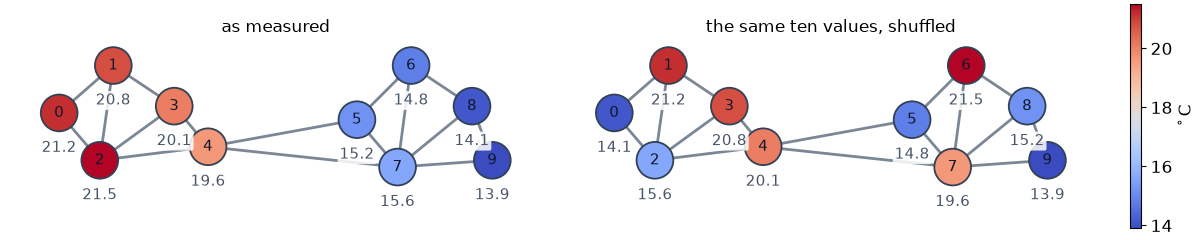

In [8]:
# Ten sensor readings, one per node (degrees C). Node order is the fixed one from 1.1.
x = np.array([21.2, 20.8, 21.5, 20.1, 19.6, 15.2, 14.8, 15.6, 14.1, 13.9])
x_shuf = rng.permutation(x)

fig, axes = plt.subplots(1, 2, figsize=(12, 2.4))
kw = dict(cmap="coolwarm", vmin=x.min(), vmax=x.max(), node_size=700)
for ax, sig, ttl in [(axes[0], x, "as measured"), (axes[1], x_shuf, "the same ten values, shuffled")]:
    coll = show_graph(ax, node_color=sig, title=ttl, **kw)
    for i in NODES:                       # write the value beside each node
        ax.annotate(f"{sig[i]:.1f}", POS[i], xytext=(0, -28), textcoords="offset points",
                    ha="center", fontsize=11, color="#475569",
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85))
fig.colorbar(coll, ax=axes[1], fraction=0.035, label="$^\\circ$C")
plt.show()

- The left one **agrees with the graph**: neighbours have similar values, and the change happens
  across the two long links. It is *smooth on this graph*.
- The right one does not. Same numbers, same edges, different arrangement.
- We now want that distinction made **quantitative and automatic**, without being told where the
  groups are. That is what the eigenvectors of $L$ do.

## 1.5  The eigenvectors are the graph's own modes

$L$ is real and symmetric, so the spectral theorem gives

$$L = U \Lambda U^\top, \qquad U = [\,u_1\;u_2\;\cdots\;u_n\,], \qquad U^\top U = I,
\qquad 0 = \lambda_1 \le \lambda_2 \le \cdots \le \lambda_n$$

- The columns $u_1,\dots,u_n$ are an **orthonormal basis** for $\mathbb{R}^n$ &mdash; built by the graph.
- $\lambda_k$ measures **how much $u_k$ changes across edges**. Small $\lambda$ = smooth mode,
  large $\lambda$ = neighbours disagree everywhere.
- That is why $\lambda_k$ is called a **graph frequency**.

| Mode | What it is |
|---|---|
| $u_1$, $\lambda_1 = 0$ | the constant vector: no variation anywhere (DC) |
| $u_2$, $\lambda_2$ | the **Fiedler vector**: smoothest non-constant pattern &rarr; the best split |
| $u_n$, $\lambda_n$ | the most edge-disagreeing pattern the graph allows |

In [9]:
lam, U = np.linalg.eigh(L)          # symmetric solver; eigenvalues ascending

# Eigenvector signs are arbitrary (-u_k is also an eigenvector). Fix them so the plots
# are reproducible: make the largest-magnitude entry positive.
U = U * np.sign(U[np.abs(U).argmax(axis=0), np.arange(n)])
lam_show = np.where(np.abs(lam) < 1e-12, 0.0, lam)     # show -0.00 as 0.00

print("lambda_1 = 0 :", abs(lam[0]) < 1e-12, "  (one zero eigenvalue = one connected component)")
print("lambda_k    =", np.round(lam_show, 3))

lambda_1 = 0 : True   (one zero eigenvalue = one connected component)
lambda_k    = [0.    0.362 1.712 2.249 3.073 3.846 4.427 4.761 5.312 6.258]


In [10]:
print("residual  ||L U - U diag(lam)||  :", np.linalg.norm(L @ U - U * lam))
print("orthonormal  ||U'U - I||         :", np.linalg.norm(U.T @ U - np.eye(n)))
print("all lambda >= 0                  :", lam.min() > -1e-12)

residual  ||L U - U diag(lam)||  : 8.322126202624575e-15
orthonormal  ||U'U - I||         : 3.468372699374578e-15
all lambda >= 0                  : True


## 1.6  The spectrum of $L$


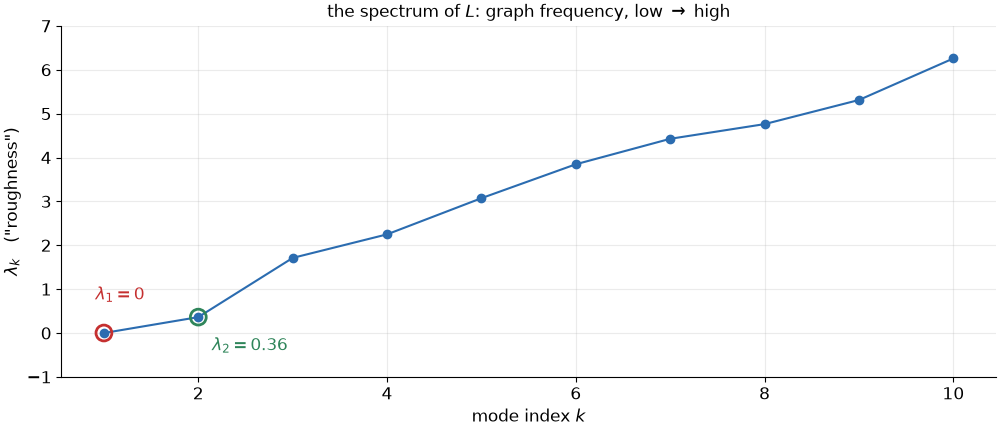

In [11]:
# The spectrum: one eigenvalue per mode, sorted. Low index = smooth, high = rough.
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(np.arange(1, n + 1), lam, "o-", color="#2b6cb0", ms=6)
for k, c in [(0, "#c53030"), (1, "#2f855a")]:
    ax.scatter([k + 1], [lam[k]], s=130, facecolor="none", edgecolor=c, lw=2, zorder=5)
ax.annotate(r"$\lambda_1 = 0$", (1, lam[0]), xytext=(-6, 24),
            textcoords="offset points", color="#c53030")
ax.annotate(r"$\lambda_2 = %.2f$" % lam[1], (2, lam[1]), xytext=(10, -24),
            textcoords="offset points", color="#2f855a")
ax.set_ylim(-1.0, lam[-1] * 1.12)
ax.set_xlabel("mode index $k$")
ax.set_ylabel(r'$\lambda_k$   ("roughness")')
ax.set_title(r"the spectrum of $L$: graph frequency, low $\to$ high")
plt.show()


## 1.6  The modes, drawn on the graph

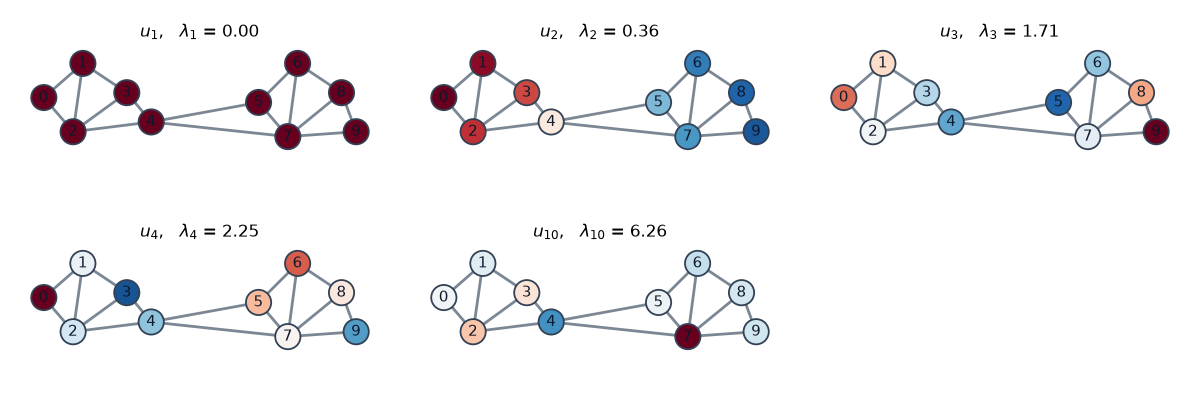

In [12]:
# The five modes drawn on the graph. Colour = that eigenvector's value at each node. Each
# panel is scaled to its own range, so read the PATTERN of signs, not the shade.
show_modes = [0, 1, 2, 3, 9]

fig, axes = plt.subplots(2, 3, figsize=(12, 4.0))
flat = axes.ravel()
for ax, k in zip(flat, show_modes):
    lim = np.abs(U[:, k]).max()
    show_graph(ax, node_color=U[:, k], cmap="RdBu_r", vmin=-lim, vmax=lim, node_size=330,
               title=rf"$u_{{{k+1}}}$,   $\lambda_{{{k+1}}}$ = {lam_show[k]:.2f}")
flat[-1].set_axis_off()
plt.show()


- $u_1$: one flat colour. No change across any edge.
- $u_2$: the two groups take opposite signs. **The graph found the split without being told** &mdash;
  and it is the same split the measured signal in §1.4 followed.
- $u_3$, $u_4$: finer structure *inside* the groups.
- $u_{10}$: neighbours alternate in sign almost everywhere. Maximum roughness.


Eigenvector signs are arbitrary, repeated eigenvalues make individual
eigenvectors non-unique (only the subspace is), and two different graphs can share a spectrum.

## 1.6  A higher eigenvalue means more sign changes

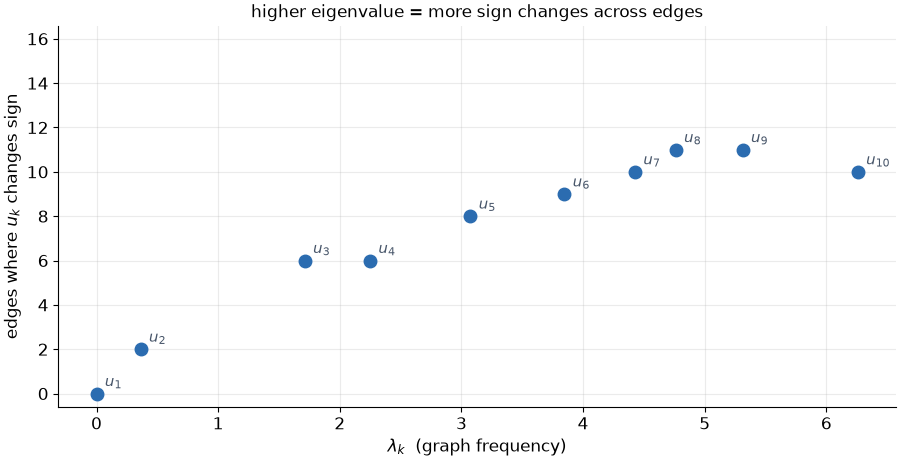

In [13]:
# Does "higher lambda" really mean "changes more often"? Count the edges across which
# a mode flips sign -- the graph analogue of counting zero crossings.
flips = [sum(U[i, k] * U[j, k] < 0 for i, j in G.edges()) for k in range(n)]

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(lam, flips, "o", ms=9, color="#2b6cb0")
for k in range(n):
    ax.annotate(f"$u_{{{k+1}}}$", (lam[k], flips[k]), xytext=(6, 5),
                textcoords="offset points", fontsize=11, color="#475569")
ax.set_xlabel(r"$\lambda_k$  (graph frequency)")
ax.set_ylabel("edges where $u_k$ changes sign")
ax.set_ylim(-0.6, G.number_of_edges() + 0.6)
ax.set_title("higher eigenvalue = more sign changes across edges")
plt.show()

## 1.6  The vocabulary, side by side

| Classical Fourier | Graph |
|---|---|
| domain: a regular grid or time axis | domain: $n$ nodes and an edge list |
| basis: $e^{i\omega t}$, fixed in advance | basis: $u_1,\dots,u_n$, **computed from the graph** |
| frequency $\omega$ | eigenvalue $\lambda_k$, the roughness of $u_k$ |
| $\hat{x}(\omega) = \langle x, e^{i\omega t}\rangle$ | $\hat{x}_k = u_k^\top x$, i.e. $\hat{x} = U^\top x$ |

Change the graph and you change the basis. There is no universal set of graph frequencies.

## 1.7  Real problems are weighted

$0/1$ edges say *related or not*. Almost every application has a **strength** instead.

| Domain | Node | Edge weight $W_{ij}$ |
|---|---|---|
| Sensor network | a station | closeness in space, e.g. $e^{-d_{ij}^2/2\sigma^2}$ |
| Road network | an intersection | capacity, or $1/\text{travel time}$ |
| Image | a pixel | similarity of intensity across the boundary |
| Time series | a sensor | correlation between the two series |
| Social / contact | a person | number of interactions |

$$W = W^\top, \qquad W_{ij} \ge 0, \qquad W_{ii} = 0 \qquad (\text{unweighted is just } W = A)$$

> **The sign convention that breaks everything if you get it wrong:**
> a **large** $W_{ij}$ means **strongly coupled**. Distance, travel time, and cost all run the
> *other* way. Convert cost to affinity explicitly &mdash; never drop a cost matrix into $W$.

In [14]:
# Our nodes have positions, so build the weights from distance with a Gaussian kernel.
P = np.array([POS[i] for i in NODES])
DIST = np.linalg.norm(P[:, None, :] - P[None, :, :], axis=-1)   # Euclidean distance, n x n

SIGMA = 1.0                      # kernel width, in the same units as the coordinates
W = A * np.exp(-DIST**2 / (2 * SIGMA**2))    # keep the SAME edges; only weight them

print("W symmetric:", np.allclose(W, W.T), " | zero diagonal:", np.allclose(np.diag(W), 0))
print("same edge set as A:", np.array_equal((W > 0), (A > 0)))
print()
print("edge        distance   weight")
for i, j in [(0, 2), (2, 4), (8, 9), (4, 5), (4, 7)]:
    tag = "   <- a long link between the groups" if i == 4 else ""
    print(f"  {i}-{j}        {DIST[i, j]:.2f}      {W[i, j]:.3f}{tag}")

W symmetric: True  | zero diagonal: True
same edge set as A: True

edge        distance   weight
  0-2        0.92      0.654
  2-4        1.61      0.273
  8-9        0.85      0.694
  4-5        2.24      0.082   <- a long link between the groups
  4-7        2.82      0.019   <- a long link between the groups


## 1.7  Weights from distance: a Gaussian kernel

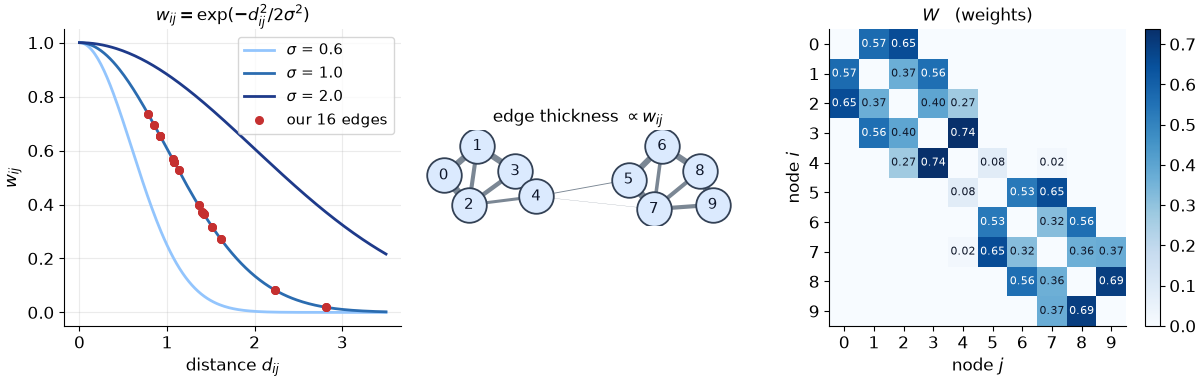

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})

dd = np.linspace(0, 3.5, 200)
for s, c in [(0.6, "#93c5fd"), (1.0, "#2b6cb0"), (2.0, "#1e3a8a")]:
    axes[0].plot(dd, np.exp(-dd**2 / (2 * s**2)), color=c, lw=2, label=f"$\\sigma$ = {s}")
axes[0].scatter(DIST[A > 0], W[A > 0], s=30, color="#c53030", zorder=5, label="our 16 edges")
axes[0].set_xlabel("distance $d_{ij}$")
axes[0].set_ylabel("$w_{ij}$")
axes[0].set_title(r"$w_{ij} = \exp(-d_{ij}^2 / 2\sigma^2)$")
axes[0].legend(fontsize=11)

widths = np.array([W[i, j] for i, j in G.edges()])
show_graph(axes[1], widths=8 * widths, title="edge thickness $\\propto w_{ij}$")
im = show_matrix(axes[2], W, "$W$   (weights)", fmt="{:.2f}", fontsize=8)
fig.colorbar(im, ax=axes[2], fraction=0.046)
plt.show()

The two links between the groups are long, so they are **weak** &mdash; $w_{45} = 0.08$ and $w_{47} = 0.02$,
against $0.27$&ndash;$0.74$ inside each group. The topology never said that; the weights do.

$\sigma$ is a free parameter, and it is **yours to justify**: small $\sigma$ and the graph falls
apart, large $\sigma$ and every weight tends to $1$. We will look at how much the answer moves
with it another time.

## 1.8  The weighted Laplacian: same formulas, weighted

$$d_i = \sum_j W_{ij} \quad (\textbf{strength}, \text{ not a count}) \qquad
D = \operatorname{diag}(d) \qquad \boxed{\,L = D - W\,}$$

- Every statement from §1.3&ndash;§1.5 survives verbatim: symmetric, $L\mathbf{1} = \mathbf{0}$,
  all $\lambda_k \geq 0$, and $L = U\Lambda U^\top$.
- What changes is the **price of disagreement**. A strong edge makes a jump between neighbours
  expensive; a weak edge nearly forgives it.
- $\lambda$ now carries the **units of the weights**. Double every weight and every $\lambda$
  doubles &mdash; so eigenvalues from two different weightings are not directly comparable.

## 1.8  $W$, $D$ and $L$ with weights

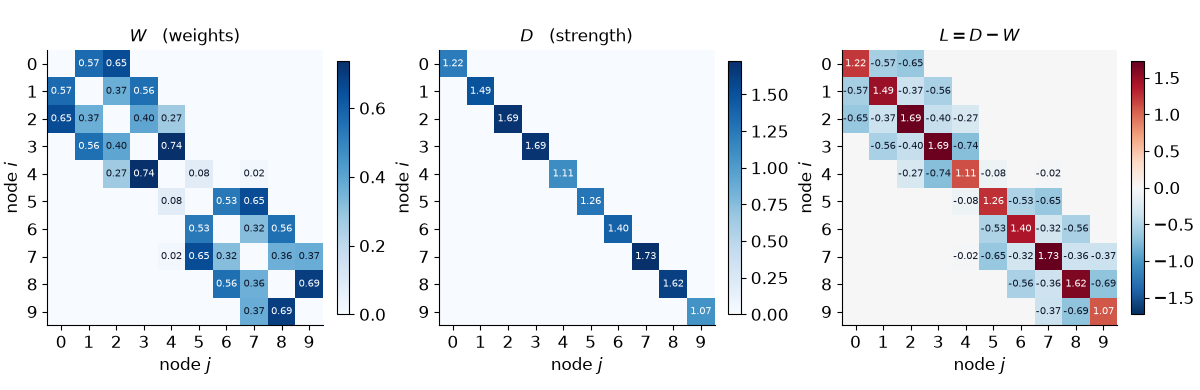

unweighted degrees (counts)  : [2. 3. 4. 3. 4. 3. 3. 5. 3. 2.]
weighted   degrees (strength): [1.22 1.49 1.69 1.69 1.11 1.26 1.4  1.73 1.62 1.07]


In [16]:
d_w = W.sum(axis=1)
D_w = np.diag(d_w)
L_w = D_w - W

fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, M, t in zip(axes, [W, D_w, L_w],
                    ["$W$   (weights)", "$D$   (strength)", "$L = D - W$"]):
    im = show_matrix(ax, M, t, fmt="{:.2f}", fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()

lam_w, U_w = np.linalg.eigh(L_w)
U_w = U_w * np.sign(U_w[np.abs(U_w).argmax(axis=0), np.arange(n)])

print("unweighted degrees (counts)  :", np.round(d, 2))
print("weighted   degrees (strength):", np.round(d_w, 2))

In [17]:
print("L symmetric:", np.allclose(L_w, L_w.T),
      "| L @ 1 == 0:", np.allclose(L_w @ np.ones(n), 0),
      "| min eigenvalue: %.2e" % lam_w.min())

L symmetric: True | L @ 1 == 0: True | min eigenvalue: -1.39e-16


## 1.9  What the weights actually changed

Same 10 nodes, same 16 edges. Only $W$ differs.

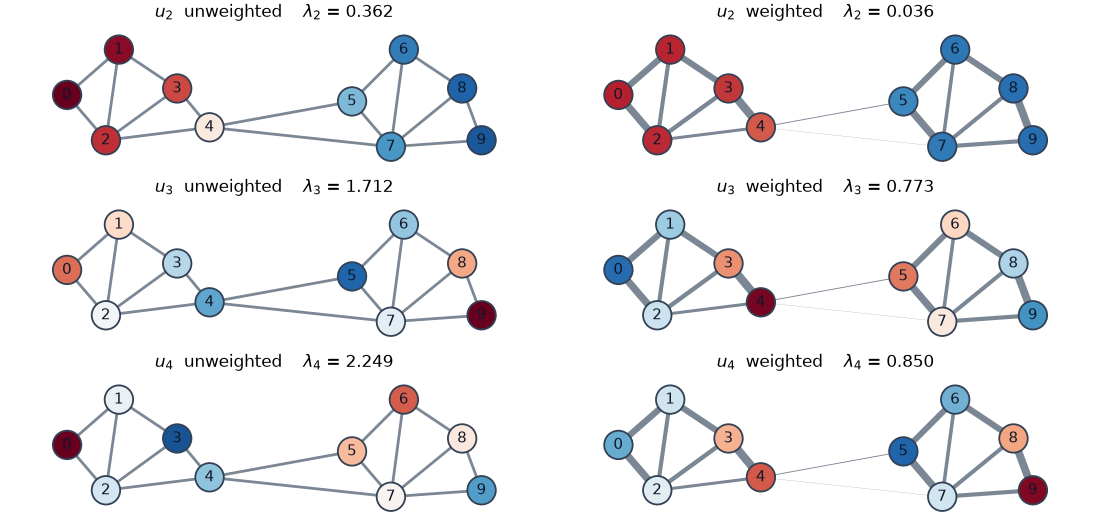

In [18]:
w_edges = 8 * np.array([W[i, j] for i, j in G.edges()])
modes = [1, 2, 3]                                    # u_2, u_3, u_4

fig, axes = plt.subplots(len(modes), 2, figsize=(11, 1.75 * len(modes)))
for row, k in enumerate(modes):
    lim = max(np.abs(U[:, k]).max(), np.abs(U_w[:, k]).max())   # one scale across the row
    for col, (vec, lm, wd, ttl) in enumerate([(U[:, k], lam[k], 2.0, "unweighted"),
                                              (U_w[:, k], lam_w[k], w_edges, "weighted")]):
        show_graph(axes[row, col], node_color=vec, cmap="RdBu_r", vmin=-lim, vmax=lim,
                   widths=wd, node_size=420,
                   title=f"$u_{{{k+1}}}$  {ttl}    $\\lambda_{{{k+1}}}$ = {lm:.3f}")
plt.show()


## 1.9  What the weights changed, in numbers

In [19]:
print(f"node 4, unweighted u_2 = {U[4, 1]:+.3f}   <- nearly on the fence")
print(f"node 4, weighted   u_2 = {U_w[4, 1]:+.3f}   <- committed to the left group")
print()
print("where each mode lives (share of its squared value in the left group):")
for k in modes:
    print(f"   u_{k+1}:  unweighted {(U[:5, k]**2).sum():.0%} left    "
          f"weighted {(U_w[:5, k]**2).sum():.0%} left")

node 4, unweighted u_2 = +0.043   <- nearly on the fence
node 4, weighted   u_2 = +0.268   <- committed to the left group

where each mode lives (share of its squared value in the left group):
   u_2:  unweighted 54% left    weighted 50% left
   u_3:  unweighted 27% left    weighted 70% left
   u_4:  unweighted 71% left    weighted 29% left


- $u_2$: **same partition** both times, $\{0,1,2,3,4\}$ against $\{5,6,7,8,9\}$. Weights did not
  overturn a clear topology &mdash; but **node 4 changed status**. Unweighted it sits at $+0.04$,
  almost undecided, because two of its four edges reach the other group. Weighted, those two edges
  are nearly worthless and it joins the left group outright.
- $u_3$ and $u_4$ **swap places**. Unweighted, $u_3$ lives mostly in the right group ($73\%$ of
  its squared value) and $u_4$ in the left; weighted, it is the other way round. Re-weighting
  reorders the modes, so **the index $k$ is not a label you can carry from one operator to another**.

## 1.9  The two spectra, each on its own scale

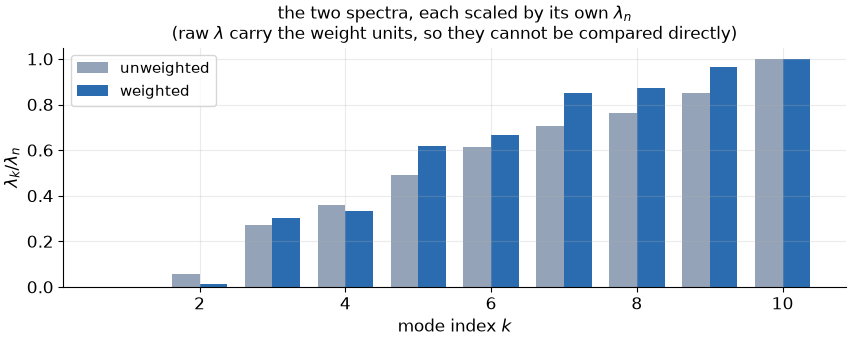

lambda_2 / lambda_n :  unweighted 0.058   weighted 0.014


In [20]:
w_ = 0.38
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.bar(np.arange(1, n + 1) - w_ / 2, lam / lam[-1], w_, label="unweighted", color="#94a3b8")
ax.bar(np.arange(1, n + 1) + w_ / 2, lam_w / lam_w[-1], w_, label="weighted", color="#2b6cb0")
ax.set_xlabel("mode index $k$")
ax.set_ylabel(r"$\lambda_k / \lambda_n$")
ax.set_title("the two spectra, each scaled by its own $\\lambda_n$\n"
             "(raw $\\lambda$ carry the weight units, so they cannot be compared directly)")
ax.legend(fontsize=11)
plt.show()

print(f"lambda_2 / lambda_n :  unweighted {lam[1]/lam[-1]:.3f}   weighted {lam_w[1]/lam_w[-1]:.3f}")

Relative to its own spectrum the weighted cut is **cheaper**: $\lambda_2/\lambda_n$ falls from
$0.058$ to $0.014$. The separation between the groups became more pronounced, not less.

Read $\lambda_2$ against *something* &mdash; here, $\lambda_n$. A bare eigenvalue with no yardstick
is not a finding.

## 1.10  Which Laplacian? Three conventions

| Operator | Definition | Spectrum | Use when |
|---|---|---|---|
| **Combinatorial** | $L = D - W$ | $[0,\;\lambda_n]$, units of $W$ | physical analogies, energy arguments, near-regular degrees |
| **Symmetric normalised** | $L_{\mathrm{sym}} = I - D^{-1/2} W D^{-1/2}$ | $[0,\,2]$, unitless | degrees vary a lot; comparing graphs of different size |
| **Random walk** | $L_{\mathrm{rw}} = I - D^{-1} W$ | same eigenvalues as $L_{\mathrm{sym}}$ | diffusion and probability arguments (not symmetric) |

- All three vanish on the constant vector, and all three have as many zero eigenvalues as the
  graph has connected components.
- $L_{\mathrm{sym}}$ measures smoothness **per unit degree**, so a hub is judged differently than under $L$.
- Coefficients $\hat{x} = U^\top x$ from different operators are **not comparable**. Pick one, state it, keep it.
- Isolated nodes ($d_i = 0$) must be handled explicitly &mdash; $D^{-1/2}$ does not exist for them.

## 1.10  $L$ and $L_{\mathrm{sym}}$ on the same graph

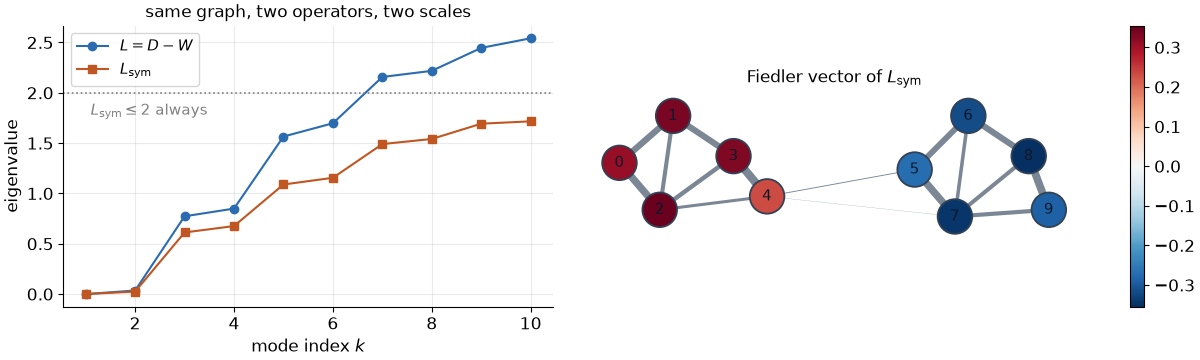

L_sym range: [0.000, 1.717]   (never exceeds 2, for any graph)
same partition as L: True
but the entries differ -- L_sym divides each node by sqrt(degree):
   L      u_2 = [ 0.34   0.333  0.327  0.31   0.268 -0.284 -0.317 -0.311 -0.331 -0.335]
   L_sym  u_2 = [ 0.309  0.336  0.351  0.333  0.231 -0.27  -0.317 -0.347 -0.355 -0.29 ]


In [21]:
Dm12 = np.diag(1.0 / np.sqrt(d_w))          # every node here has positive strength
L_sym = np.eye(n) - Dm12 @ W @ Dm12
lam_sym, U_sym = np.linalg.eigh(L_sym)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].plot(np.arange(1, n + 1), lam_w, "o-", color="#2b6cb0", label="$L = D - W$")
axes[0].plot(np.arange(1, n + 1), lam_sym, "s-", color="#c05621", label="$L_{\\mathrm{sym}}$")
axes[0].axhline(2, color="gray", ls=":", lw=1.2)
axes[0].annotate("$L_{\\mathrm{sym}} \\leq 2$ always", (1.1, 2), xytext=(0, -16),
                 textcoords="offset points", color="gray", fontsize=11)
axes[0].set_xlabel("mode index $k$")
axes[0].set_ylabel("eigenvalue")
axes[0].set_title("same graph, two operators, two scales")
axes[0].legend(fontsize=11)

f_sym = U_sym[:, 1] * np.sign(U_sym[0, 1] * U_w[0, 1])   # align the arbitrary global sign
lim = max(np.abs(f_sym).max(), np.abs(U_w[:, 1]).max())
coll = show_graph(axes[1], node_color=f_sym, cmap="RdBu_r", vmin=-lim, vmax=lim,
                  widths=8 * np.array([W[i, j] for i, j in G.edges()]),
                  title="Fiedler vector of $L_{\\mathrm{sym}}$")
fig.colorbar(coll, ax=axes[1], fraction=0.035)
plt.show()

print("L_sym range: [%.3f, %.3f]   (never exceeds 2, for any graph)"
      % (abs(lam_sym[0]), lam_sym[-1]))
print("same partition as L:", bool(np.all((f_sym > 0) == (U_w[:, 1] > 0))))
print("but the entries differ -- L_sym divides each node by sqrt(degree):")
print("   L      u_2 =", np.round(U_w[:, 1], 3))
print("   L_sym  u_2 =", np.round(f_sym, 3))

## Part 1 &mdash; what to carry forward

| Object | What it is | Why it matters |
|---|---|---|
| $W$ (or $A$) | who is coupled to whom, how strongly | the entire model lives here |
| $L = D - W$ | difference operator | measures how much a signal changes across edges |
| $\lambda_k$ | roughness of mode $k$ | **graph frequency** |
| $u_k$ | mode $k$ | the graph's own basis, sorted smooth to rough |
| $\hat{x} = U^\top x$ | graph Fourier transform | Part 3 |

**Three things to remember:**

1. The basis is **computed, not assumed**. Change the graph and every frequency changes.
2. A raw eigenvalue means nothing on its own. Report it against a yardstick.
3. The weighting function is a **modelling decision**, and it moves the answer.

*Next: Part 2 &mdash; the same eigenproblem, on a line of masses and springs.*

# Part 2 &mdash; Springs and masses

## 2.1  It is the same eigenproblem

$n$ masses, each $m$, joined in a line by springs of stiffness $k$, with the bottom one bolted
down. Let $x_i(t)$ be the displacement of mass $i$ **from its rest position**.

$$M\ddot{x} + Kx = 0, \qquad M = mI, \qquad K = k\,L$$

Look for a motion in which every mass oscillates at the same frequency, $x(t) = u\cos(\omega t)$:

$$-\omega^2 m\,u + k\,L\,u = 0 \qquad\Longrightarrow\qquad
L\,u = \frac{m\omega^2}{k}\,u \qquad\Longrightarrow\qquad
\boxed{\;\lambda_k = \frac{m\,\omega_k^2}{k}\;,\qquad \omega_k = \sqrt{\tfrac{k}{m}\,\lambda_k}\;}$$


## 2.1  Masses and springs, read as a graph

| Spring&ndash;mass system | Graph |
|---|---|
| mass $i$ | node $i$ |
| spring between $i$ and $j$ | edge $\{i,j\}$ |
| spring stiffness $k$ [N/m] | edge weight $W_{ij}$ |
| **displacement $x_i(t)$ [m]** | **graph signal $x \in \mathbb{R}^n$** |
| stiffness matrix $K$ [N/m] | $k\,L$ |
| mode shape $\phi_k$ | eigenvector $u_k$ |
| natural frequency $\omega_k$ [rad/s] | $\sqrt{(k/m)\,\lambda_k}$ |


## 2.1  The column, its graph, and its five modes

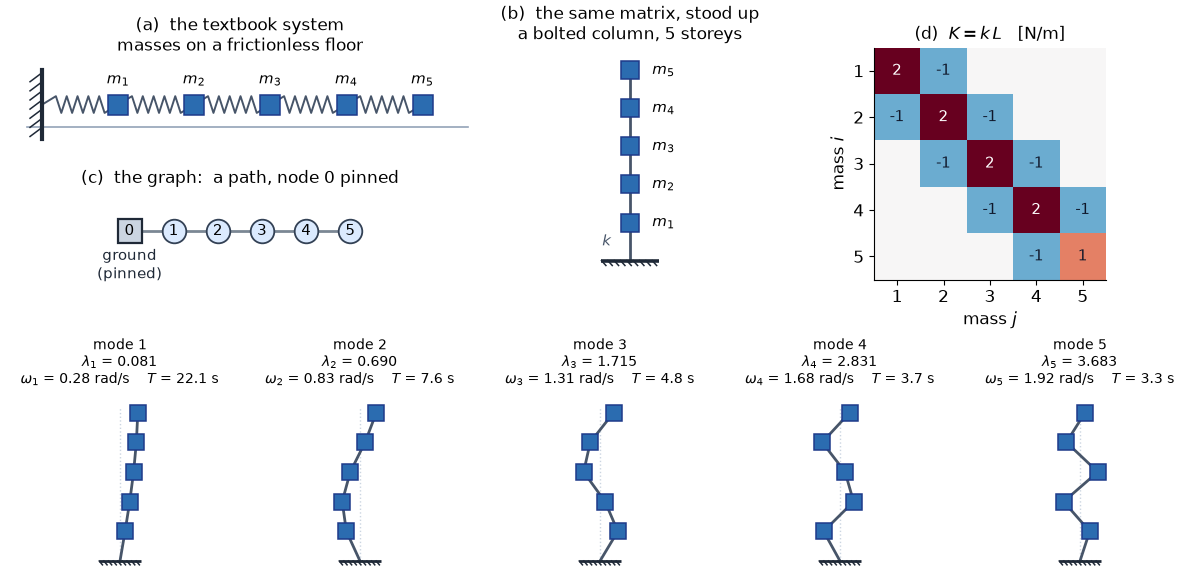

In [22]:
from matplotlib.patches import Rectangle

# ---- the system ------------------------------------------------------------------
NM, m_mass, k_spr = 5, 1.0, 1.0          # masses [-], mass [kg], stiffness [N/m]

Gcol = nx.path_graph(NM + 1)             # node 0 = the ground, nodes 1..5 = the masses
Lcol = nx.laplacian_matrix(Gcol).toarray().astype(float)
freeN = np.arange(1, NM + 1)
L_pin = Lcol[np.ix_(freeN, freeN)]       # ground row/column deleted  ->  5 x 5
K = k_spr * L_pin                        # stiffness matrix [N/m]

lam_c, Phi = np.linalg.eigh(L_pin)       # graph eigenvalues / eigenvectors
Phi = Phi * np.sign(Phi[-1])             # sign convention: top storey positive
omega = np.sqrt(k_spr / m_mass * lam_c)  # natural frequencies [rad/s], from the GRAPH
Phi_u = Phi / np.abs(Phi).max(axis=0)    # rescaled so each mode peaks at 1

# ---- small drawing helpers -------------------------------------------------------
def coil(p0, p1, turns=5, amp=0.11):
    "Zigzag points for a spring drawn between two endpoints."
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    v = p1 - p0; ln = np.linalg.norm(v)
    uv = v / ln; nv = np.array([-uv[1], uv[0]])
    s = np.linspace(0.18, 0.82, 2 * turns)
    off = amp * np.where(np.arange(2 * turns) % 2 == 0, 1.0, -1.0)
    return np.array([p0] + [p0 + uv * ln * si + nv * oi for si, oi in zip(s, off)] + [p1])

def hatched_base(ax, x0, x1, y, down=True, lw=2.6):
    "A fixed support: a solid line with diagonal ticks on one side."
    ax.plot([x0, x1], [y, y], color="#1f2937", lw=lw, zorder=4, solid_capstyle="butt")
    step = (x1 - x0) / 9
    for t in np.arange(x0, x1 - step * 0.5, step):
        dy = -0.13 if down else 0.13
        ax.plot([t, t + step * 0.7], [y, y + dy], color="#1f2937", lw=1.1, zorder=4)

def draw_column(ax, disp, ylev, color="#2b6cb0", ms=13, lw=2.0, alpha=1.0, zorder=3):
    "Column line from the ground through every displaced floor, plus the masses."
    ax.plot(np.r_[0.0, disp], np.r_[0.0, ylev], color="#475569", lw=lw,
            alpha=alpha, zorder=zorder)
    ax.plot(disp, ylev, "s", ms=ms, color=color, mec="#1e3a8a", mew=1.1,
            alpha=alpha, zorder=zorder + 1)

ylev = np.arange(1, NM + 1, dtype=float)

# ---- the figure ------------------------------------------------------------------
fig = plt.figure(figsize=(12, 5.8))
gs = fig.add_gridspec(3, 20, height_ratios=[0.62, 0.48, 1.0])
ax_chain = fig.add_subplot(gs[0, 0:8])
ax_graph = fig.add_subplot(gs[1, 0:8])
ax_col = fig.add_subplot(gs[0:2, 8:13])
ax_K = fig.add_subplot(gs[0:2, 13:20])

# (a) the textbook picture: masses on a frictionless floor, wall on the left
xr = np.arange(1, NM + 1, dtype=float)
ax_chain.plot([0, 0], [-0.45, 0.45], color="#1f2937", lw=3, zorder=4)
for yy in np.linspace(-0.42, 0.30, 7):
    ax_chain.plot([-0.16, 0], [yy, yy + 0.12], color="#1f2937", lw=1.1, zorder=4)
ax_chain.plot([-0.2, NM + 0.6], [-0.30, -0.30], color="#94a3b8", lw=1.2)
for p0, p1 in zip(np.r_[0.0, xr[:-1]], xr):
    c = coil((p0, 0), (p1, 0))
    ax_chain.plot(c[:, 0], c[:, 1], color="#475569", lw=1.4, zorder=2)
ax_chain.plot(xr, np.zeros(NM), "s", ms=15, color="#2b6cb0", mec="#1e3a8a", mew=1.1, zorder=3)
for i, xx in enumerate(xr):
    ax_chain.annotate(f"$m_{i+1}$", (xx, 0), xytext=(0, 15), textcoords="offset points",
                      ha="center", fontsize=11)
ax_chain.set_xlim(-0.5, NM + 0.7); ax_chain.set_ylim(-0.6, 0.6)
ax_chain.set_aspect("equal"); ax_chain.set_axis_off()
ax_chain.set_title("(a)  the textbook system\nmasses on a frictionless floor", fontsize=12)

# (b) the same thing stood up: a bolted column, storeys swaying sideways
hatched_base(ax_col, -0.75, 0.75, 0.0)
draw_column(ax_col, np.zeros(NM), ylev)
for i, yy in enumerate(ylev):
    ax_col.annotate(f"$m_{i+1}$", (0, yy), xytext=(16, 0), textcoords="offset points",
                    va="center", fontsize=11)
ax_col.annotate("$k$", (0, 0.5), xytext=(-20, 0), textcoords="offset points",
                va="center", fontsize=11, color="#475569")
ax_col.set_xlim(-1.5, 1.5); ax_col.set_ylim(-0.5, NM + 0.6)
ax_col.set_aspect("equal"); ax_col.set_axis_off()
ax_col.set_title("(b)  the same matrix, stood up\na bolted column, 5 storeys", fontsize=12)

# (c) the graph: a path, with the ground node pinned
gx = np.arange(NM + 1, dtype=float)
ax_graph.plot(gx, np.zeros(NM + 1), color="#7b8794", lw=2, zorder=1)
ax_graph.plot(gx[1:], np.zeros(NM), "o", ms=17, color="#dbeafe", mec="#334155", mew=1.3, zorder=3)
ax_graph.plot([0], [0], "s", ms=17, color="#cbd5e1", mec="#1f2937", mew=1.6, zorder=3)
for i in range(NM + 1):
    ax_graph.annotate(str(i), (gx[i], 0), ha="center", va="center", fontsize=11, zorder=4)
ax_graph.annotate("ground\n(pinned)", (0, 0), xytext=(0, -34), textcoords="offset points",
                  ha="center", fontsize=11, color="#1f2937")
ax_graph.set_xlim(-0.8, NM + 0.8); ax_graph.set_ylim(-1.1, 0.9)
ax_graph.set_aspect("equal"); ax_graph.set_axis_off()
ax_graph.set_title("(c)  the graph:  a path, node 0 pinned", fontsize=12)

# (d) the stiffness matrix
im = show_matrix(ax_K, K, "(d)  $K = k\\,L$   [N/m]", fmt="{:.0f}", fontsize=11)
ax_K.set_xlabel("mass $j$"); ax_K.set_ylabel("mass $i$")
ax_K.set_xticklabels(range(1, NM + 1)); ax_K.set_yticklabels(range(1, NM + 1))

# (e) the five mode shapes, with their frequencies
for kk in range(NM):
    ax = fig.add_subplot(gs[2, 4 * kk:4 * kk + 4])
    hatched_base(ax, -0.7, 0.7, 0.0, lw=2.0)
    ax.plot([0, 0], [0, NM + 0.2], color="#cbd5e1", lw=1.0, ls=":", zorder=1)  # undeformed
    draw_column(ax, 0.6 * Phi_u[:, kk], ylev, ms=11)
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-0.5, NM + 0.7)
    ax.set_aspect("equal"); ax.set_axis_off()
    ax.set_title(f"mode {kk+1}\n$\\lambda_{{{kk+1}}}$ = {lam_c[kk]:.3f}\n"
                 f"$\\omega_{{{kk+1}}}$ = {omega[kk]:.2f} rad/s    $T$ = {2*np.pi/omega[kk]:.1f} s",
                 fontsize=10)
plt.show()


In [23]:
om_from_K = np.sqrt(np.linalg.eigvalsh(K) / m_mass)
print(f"frequencies from the physics (eigenvalues of K, divided by m) vs "
      f"sqrt(k/m * lambda) from the GRAPH: max difference {np.abs(om_from_K - omega).max():.1e}")
print("omega_k [rad/s] =", np.round(omega, 4))
print("lambda_k        =", np.round(lam_c, 4), "   (k/m = 1 here, so omega_k = sqrt(lambda_k))")

frequencies from the physics (eigenvalues of K, divided by m) vs sqrt(k/m * lambda) from the GRAPH: max difference 2.2e-16
omega_k [rad/s] = [0.2846 0.8308 1.3097 1.6825 1.919 ]
lambda_k        = [0.081  0.6903 1.7154 2.8308 3.6825]    (k/m = 1 here, so omega_k = sqrt(lambda_k))


## 2.1  What carries over from Part 1

- The eigenvalues of the graph **are** the squared natural frequencies, up to the constant $k/m$.
  "Low graph frequency" is not a metaphor here &mdash; it is *slow*, in rad/s.
- The graph is the path **ground&ndash;$m_1$&ndash;$\cdots$&ndash;$m_5$**. Bolting the base down **pins**
  that node: delete its row and column from $L$. That is what removes the $\lambda_1 = 0$ constant
  mode from Part 1 &mdash; a bolted column cannot drift as a rigid body, so every $\omega_k > 0$.
- In $K$ below, the last diagonal entry is $1$, not $2$: the top mass has a spring below it and
  nothing above. That is just its degree in the graph.
- This is a 1-D chain, so the modes come out as sine half-waves. **Part 1's graph was not a chain**,
  and that is the whole point: the eigenproblem does not care about the geometry, only the edges.


## 2.2  Watch it move

Release the column in one mode shape and let go. Each panel below runs on **the same clock**.


In [24]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

CASES = [("mode 1", np.array([0.40, 0, 0, 0, 0])),
         ("mode 2", np.array([0, 0.40, 0, 0, 0])),
         ("mode 3, half amplitude", np.array([0, 0, 0.20, 0, 0])),
         ("modes 1 + 2 + 3", np.array([0.40, 0.25, 0.15, 0, 0]))]

NFR = 96
T_END = 2 * np.pi / omega[0]                       # one full period of the slowest mode
tt = np.linspace(0, T_END, NFR)
# x(t) = Phi @ (a_k cos(omega_k t)) -- each mode keeps its OWN frequency
hist = [Phi_u @ (a[:, None] * np.cos(omega[:, None] * tt[None, :])) for _, a in CASES]

def case_title(name, a):
    ks = np.flatnonzero(a)
    fr = " + ".join(f"$\\omega_{{{k+1}}}$={omega[k]:.2f}" for k in ks)
    amp = ", ".join(f"{a[k]:.2f}" for k in ks)
    word = "amplitude" if len(ks) == 1 else "amplitudes"
    return f"{name}\n{fr} rad/s\nmodal {word} {amp} m"

# ---- the animation: the four columns, on one clock -------------------------------
# Displacements are DRAWN magnified, the way mode-shape plots always are. The numbers
# in the titles and in the traces below are the real ones.
MAG = 3.0
XLIM = 1.06 * MAG * max(np.abs(h).max() for h in hist)

figA, axesA = plt.subplots(1, 4, figsize=(12, 4.2), dpi=100)
figA.get_layout_engine().set(rect=(0.0, 0.05, 1.0, 0.95))   # reserve room for the clock
col_lines, mass_pts = [], []
for c, (name, a) in enumerate(CASES):
    ax = axesA[c]
    hatched_base(ax, -0.95, 0.95, 0.0, lw=2.2)
    ax.plot([0, 0], [0, NM + 0.2], color="#cbd5e1", lw=1.0, ls=":", zorder=1)
    ln, = ax.plot([], [], color="#475569", lw=2.2, zorder=2)
    mp, = ax.plot([], [], "s", ms=15, color="#2b6cb0", mec="#1e3a8a", mew=1.1, zorder=3)
    col_lines.append(ln); mass_pts.append(mp)
    ax.set_xlim(-XLIM, XLIM); ax.set_ylim(-0.45, NM + 0.55)
    ax.set_aspect("equal"); ax.set_axis_off()
    ax.set_title(case_title(name, a), fontsize=11)
clock = figA.text(0.5, 0.015, "", ha="center", fontsize=12, color="#475569")

def update(f):
    for c in range(len(CASES)):
        xs = MAG * hist[c][:, f]
        col_lines[c].set_data(np.r_[0.0, xs], np.r_[0.0, ylev])
        mass_pts[c].set_data(xs, ylev)
    clock.set_text(f"t = {tt[f]:5.1f} s        "
                   f"lateral displacement drawn $\\times${MAG:g}")
    return col_lines + mass_pts + [clock]

ani = FuncAnimation(figA, update, frames=NFR, interval=55, blit=False)
display(HTML(ani.to_jshtml(default_mode="loop")))
plt.close(figA)


## 2.2  What each column shows

| What you are looking at | What it shows |
|---|---|
| **mode 1**, amplitude 0.40 m | every storey sways the same way &mdash; slowest, $T_1 \approx 22$ s |
| **mode 2**, amplitude 0.40 m | one sign change up the height &mdash; about $3\times$ faster |
| **mode 3**, amplitude **0.20 m** | two sign changes, faster again. *Half the size, identical frequency* |
| **modes 1+2+3**, amplitudes 0.40 / 0.25 / 0.15 m | the motion looks complicated, but it is only three modes added up |


## 2.2  The same motions, read off the top mass

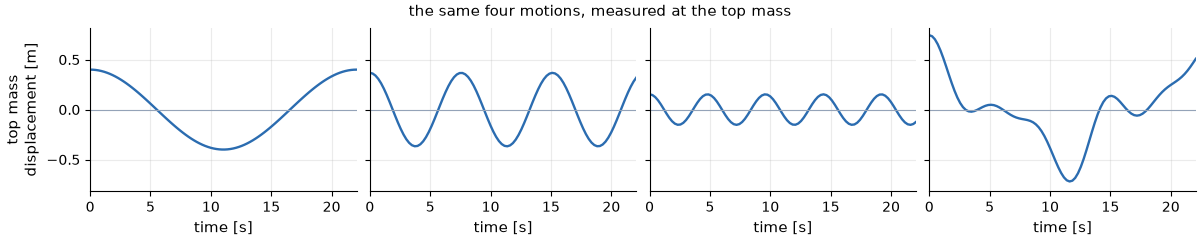

In [25]:
# ---- the same four motions, read off the top mass --------------------------------
ytop = 1.1 * max(np.abs(h[-1]).max() for h in hist)
figB, axesB = plt.subplots(1, 4, figsize=(12, 2.4), sharey=True)
for c, (name, a) in enumerate(CASES):
    ax = axesB[c]
    ax.plot(tt, hist[c][-1], color="#2b6cb0", lw=1.7)
    ax.axhline(0, color="#94a3b8", lw=0.8)
    ax.set_xlim(0, T_END); ax.set_ylim(-ytop, ytop)
    ax.set_xlabel("time [s]", fontsize=11)
    ax.tick_params(labelsize=10)
    ax.grid(True, alpha=0.25)
axesB[0].set_ylabel("top mass\ndisplacement [m]", fontsize=11)
figB.suptitle("the same four motions, measured at the top mass", fontsize=11)
plt.show()

- A **mode shape never changes shape** as it oscillates. It scales up and down by $\cos(\omega_k t)$.
- **Amplitude sets the size. The eigenvalue sets the speed.** They are independent.
- The mixed panel is the point of the whole course: the amplitudes $0.40, 0.25, 0.15$ **are** the
  graph Fourier coefficients $\hat{x}_k$ of that motion. Measuring the wobble and asking
  *how much of each mode is in it* is exactly the transform from Part 1.
- Assumptions: no damping, small displacements, linear springs, displacement measured from static
  equilibrium (so gravity drops out).


## Part 2 &mdash; what to carry forward

| | |
|---|---|
| **The signal** | the displacements $x_i(t)$, one number per mass |
| **The operator** | $K = k\,L$ &mdash; the graph Laplacian with units bolted on |
| **The modes** | eigenvectors of $L$, and the structure genuinely moves in them |
| **The frequencies** | $\omega_k = \sqrt{(k/m)\lambda_k}$ &mdash; the graph spectrum, in rad/s |
| **The transform** | decomposing a measured motion into modal amplitudes **is** the GFT |

For a chain this is standard structural dynamics. The value of the graph view is that **nothing
above used the fact that it was a chain** &mdash; swap in any graph, weighted or not, and the same
eigenproblem runs. That is what lets us do it next on a network of weather stations.

*Next: Part 3 &mdash; temperature sensors.*

# Part 3 &mdash; Temperature sensors

## 3.1  The data

**NOAA GHCN-Daily**, daily maximum temperature, Connecticut / Rhode Island / Massachusetts.

| | |
|---|---|
| Stations | **85** (kept those reporting on $\geq 90\%$ of days) |
| Days | **1096** &mdash; all of 2015, 2016, 2017 |
| Signal | one temperature per station per day &mdash; a graph signal, one per day |
| Quality control | blank `QFLAG` only; 28 flagged observations dropped |

**The seasonal cycle is about $10\times$ the spatial structure.** Every station is warm in July.
That is true and useless, so we work with the **daily anomaly**:

$$z_t \;=\; y_t - \bar{y}_t\mathbf{1}, \qquad \bar{y}_t = \text{mean over the stations reporting on day } t$$

- What is left is *who is warmer than the region today* &mdash; the part that says something about connections.
- Each $z_t$ is orthogonal to $\mathbf{1}$ by construction. Remember that; §3.6 collects on it.

In [26]:
import temps as T           # the pipeline: loading, QC, anomalies, splits, fitting
import glearn as glearn_

C_GEO, C_KALO, C_PCA, C_BASE = "#e07a3f", "#2b6cb0", "#2f855a", "#94a3b8"

print(f"stations N = {T.N}   days = {len(T.all_days)}   "
      f"flagged observations dropped = {T.n_flagged}")
print(f"median inter-station distance = {T.med_d/1000:.0f} km")
print(f"split (season-balanced blocks, gap days between):  "
      f"train {len(T.train_days)}   validation {len(T.val_days)}   test {len(T.test_days)}")

def station_map(ax, c, cmap, title, label, vmin=None, vmax=None, s=26):
    T.draw_states(ax)
    sc = ax.scatter(T.PK[:, 0], T.PK[:, 1], c=c, cmap=cmap, vmin=vmin, vmax=vmax, s=s,
                    edgecolor="0.3", linewidth=0.3, zorder=3)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(title)
    if label is not None:
        ax.figure.colorbar(sc, ax=ax, fraction=0.046, label=label)
    return sc


stations N = 85   days = 1096   flagged observations dropped = 28
median inter-station distance = 109 km
split (season-balanced blocks, gap days between):  train 439   validation 118   test 116


## 3.1  85 stations, one day, three years

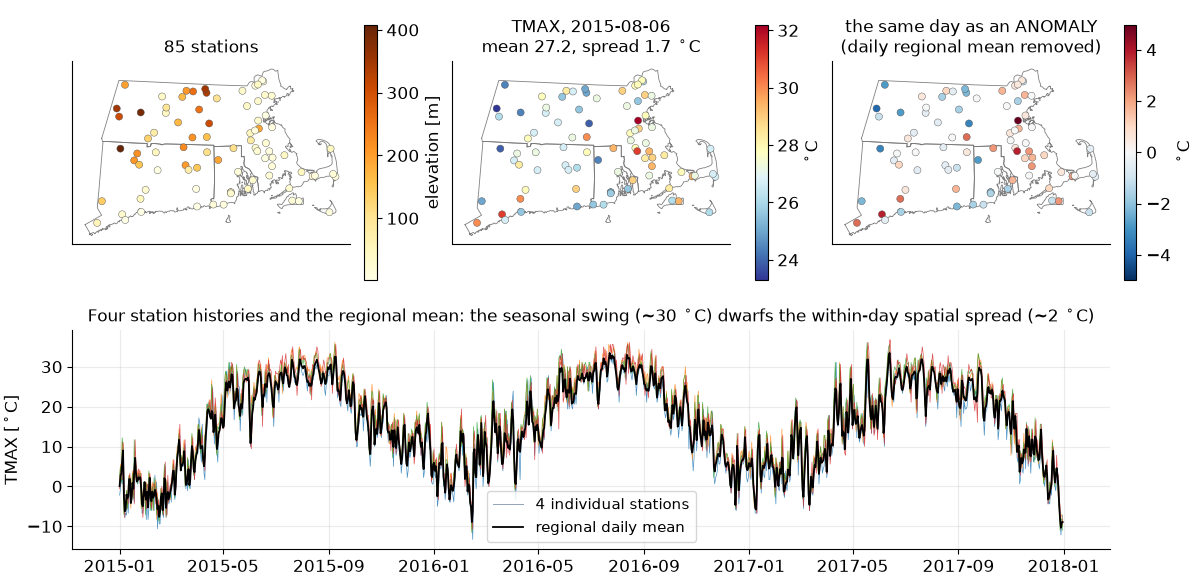

In [27]:
fig = plt.figure(figsize=(12, 5.8))
gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1.0])
DAY = "2015-08-06"
j = list(T.Ywide.columns).index(DAY)

station_map(fig.add_subplot(gs[0, 0]), T.elev, "YlOrBr", f"{T.N} stations", "elevation [m]")
station_map(fig.add_subplot(gs[0, 1]), T.Y[:, j], "RdYlBu_r",
            f"TMAX, {DAY}\nmean {np.nanmean(T.Y[:, j]):.1f}, "
            f"spread {np.nanstd(T.Y[:, j]):.1f} $^\\circ$C", "$^\\circ$C")
lim = np.nanmax(np.abs(T.Zfull[:, j]))
station_map(fig.add_subplot(gs[0, 2]), T.Zfull[:, j], "RdBu_r",
            "the same day as an ANOMALY\n(daily regional mean removed)", "$^\\circ$C",
            vmin=-lim, vmax=lim)

ax = fig.add_subplot(gs[1, :])
for i in rng.choice(T.N, 4, replace=False):
    ax.plot(T.dates, T.Y[i], lw=0.5, alpha=0.8)
ax.plot([], [], lw=0.7, color="#94a3b8", label="4 individual stations")
ax.plot(T.dates, np.nanmean(T.Y, axis=0), lw=1.3, color="black", label="regional daily mean")
ax.set_ylabel("TMAX [$^\\circ$C]")
ax.set_title("Four station histories and the regional mean: the seasonal swing (~30 $^\\circ$C) "
             "dwarfs the within-day spatial spread (~2 $^\\circ$C)")
ax.legend(fontsize=11)
plt.show()

## 3.2  The task, and a graph built from geography alone

**Task.** Hide **17 of the 85** stations at random, reconstruct them from the other 68, report
RMSE in $^\circ$C. Four different hidden sets per day, identical for every method.

$$\hat{x} \;=\; \arg\min_x\;\underbrace{\textstyle\sum_{i \,\text{visible}} (x_i - y_i)^2}_{\text{match what we saw}}
\;+\; \gamma\,\underbrace{x^\top L x}_{\text{be smooth on the graph}}$$

That second term is Part 1's Dirichlet energy. **The graph is the entire prior.**

**The geographic graph:** $W_{ij} = \exp(-d_{ij}^2/2\sigma^2)$ on physical distance, kept only
between $k$ nearest neighbours. $\sigma$, $k$ and $\gamma$ chosen on **validation** days; test days
are touched once, at the end.

| | test RMSE [$^\circ$C] |
|---|---|
| predict the visible-station mean (no model at all) | 2.845 |
| elevation regression | 2.788 |
| **geographic graph** | **2.475** |

Three-quarters of a degree of the error is gone, and the graph bought **13%** over doing nothing.

## 3.2  The geographic graph at work

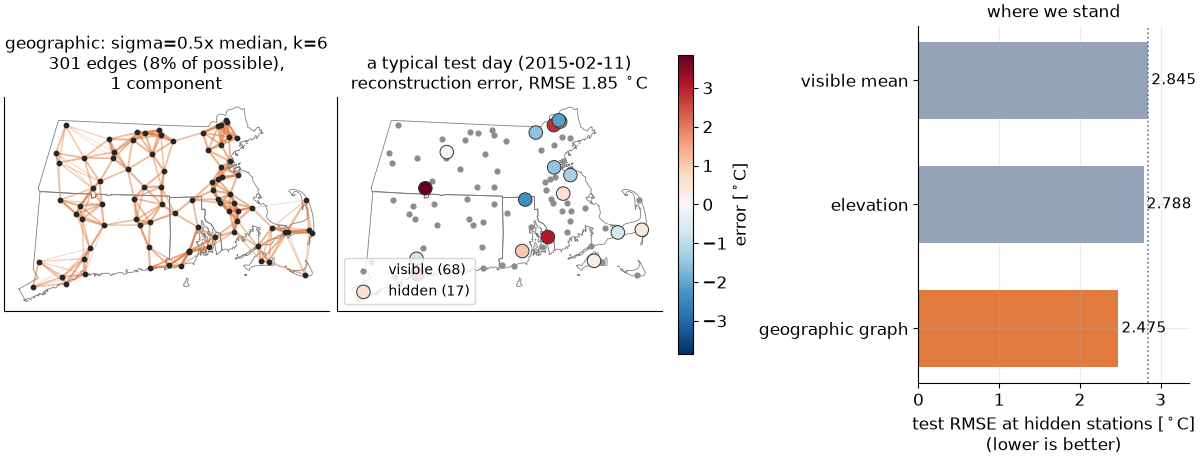

In [28]:
geo_best, geo_rows = T.select_on_validation(T.build_geographic())
w_geo = T.trace_normalised(geo_best["w"])
L_geo = T.L_of(w_geo)

RMSE = {}
RMSE["visible mean"] = T.eval_baseline("mean", T.test_days, T.test_masks)
RMSE["elevation"] = T.eval_baseline("elev", T.test_days, T.test_masks)
RMSE["geographic graph"] = T.eval_graph(geo_best["w"], T.test_days, T.test_masks,
                                        [geo_best["gamma"]])[1]

def graph_on_map(ax, w, title, color=C_KALO, max_edges=1200):
    thr = 1e-8 * w.max()
    for k in np.argsort(-w)[:max_edges]:
        if w[k] <= thr:
            break
        i, j_ = T.ei.iu[0][k], T.ei.iu[1][k]
        ax.plot([T.PK[i, 0], T.PK[j_, 0]], [T.PK[i, 1], T.PK[j_, 1]], color=color,
                lw=0.15 + 1.6 * (w[k] / w.max()), alpha=0.15 + 0.5 * (w[k] / w.max()), zorder=1)
    T.draw_states(ax)
    ax.scatter(T.PK[:, 0], T.PK[:, 1], s=10, c="0.15", zorder=3)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    nz = int((w > thr).sum())
    ax.set_title(f"{title}\n{nz} edges ({100*nz/T.ei.m:.0f}% of possible),\n"
                 f"{glearn_.n_components(T.L_of(w))} component")

def rmse_bars(ax, entries, title):
    names = list(entries)
    vals = [entries[k][0] for k in names]
    cols = [entries[k][1] for k in names]
    y = np.arange(len(names))
    ax.barh(y, vals, color=cols, height=0.62)
    for yy, v in zip(y, vals):
        ax.text(v + 0.04, yy, f"{v:.3f}", va="center", fontsize=11)
    ax.axvline(vals[0], color="#64748b", ls=":", lw=1.2)
    ax.set_yticks(y); ax.set_yticklabels(names)
    ax.invert_yaxis(); ax.set_xlim(0, 3.35)
    ax.set_xlabel("test RMSE at hidden stations [$^\\circ$C]\n(lower is better)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
graph_on_map(axes[0], w_geo, f"geographic: {geo_best['label']}", color=C_GEO)

d_geo_day = T.per_day_rmse(T.test_days, T.test_masks, w=geo_best["w"], gamma=geo_best["gamma"])
t_show = T.test_days[np.argmin(np.abs(d_geo_day - np.median(d_geo_day)))]   # a typical day
hid = T.test_masks[t_show][0]
yhat = T.reconstruct_day(L_geo, T.Y[:, t_show], hid, geo_best["gamma"])
err = yhat[hid] - T.Y[hid, t_show]
vis = np.setdiff1d(np.arange(T.N), hid)
ax = axes[1]
T.draw_states(ax)
ax.scatter(T.PK[vis, 0], T.PK[vis, 1], s=12, c="0.55", zorder=2, label="visible (68)")
lim = np.abs(err).max()
sc = ax.scatter(T.PK[hid, 0], T.PK[hid, 1], c=err, cmap="RdBu_r", vmin=-lim, vmax=lim,
                s=95, edgecolor="0.2", linewidth=0.7, zorder=3, label="hidden (17)")
fig.colorbar(sc, ax=ax, fraction=0.046, label="error [$^\\circ$C]")
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(fontsize=10, loc="lower left")
ax.set_title(f"a typical test day ({T.dates[t_show].date()})\n"
             f"reconstruction error, RMSE {np.sqrt((err**2).mean()):.2f} $^\\circ$C")

rmse_bars(axes[2], {"visible mean": (RMSE["visible mean"], C_BASE),
                    "elevation": (RMSE["elevation"], C_BASE),
                    "geographic graph": (RMSE["geographic graph"], C_GEO)},
          "where we stand")
plt.show()

## 3.3  Why geography is the wrong graph here

The geographic graph assumes **close $\Rightarrow$ coupled**. So ask the data what the dominant
pattern in these anomalies actually *is* &mdash; take its leading principal component.

**It is not weather. It is the instrument.**

- PC1 carries **53% of the variance** and splits the stations almost perfectly by GHCN network
  code: all **31 airport (`USW`)** stations on one side, **43 of 52 volunteer co-op (`USC`)**
  stations on the other.
- Position and elevation explain only $R^2 = 0.14$ of it. On the geographic graph its roughness is
  $0.92$ &mdash; statistically indistinguishable from a **random** vector ($0.996 \pm 0.068$).
- Same-network pairs have median anomaly correlation $+0.48$; cross-network pairs $-0.55$.
  That is the split you can see in the scatter, and it has nothing to do with distance.

The likely mechanism is **time-of-observation**: co-op observers read a 24-hour maximum ending in
the morning, airport stations run midnight to midnight, so the two networks assign the same warm
air mass to different calendar days. This is a documented feature of GHCN-Daily, not a bug in our
handling.

> A graph whose every mode is spatially smooth **cannot represent the biggest thing in this signal.**
> That is why the geographic construction only bought 13%, and no amount of tuning $\sigma$ or $k$
> would have fixed it.

## 3.3  The dominant pattern is the instrument

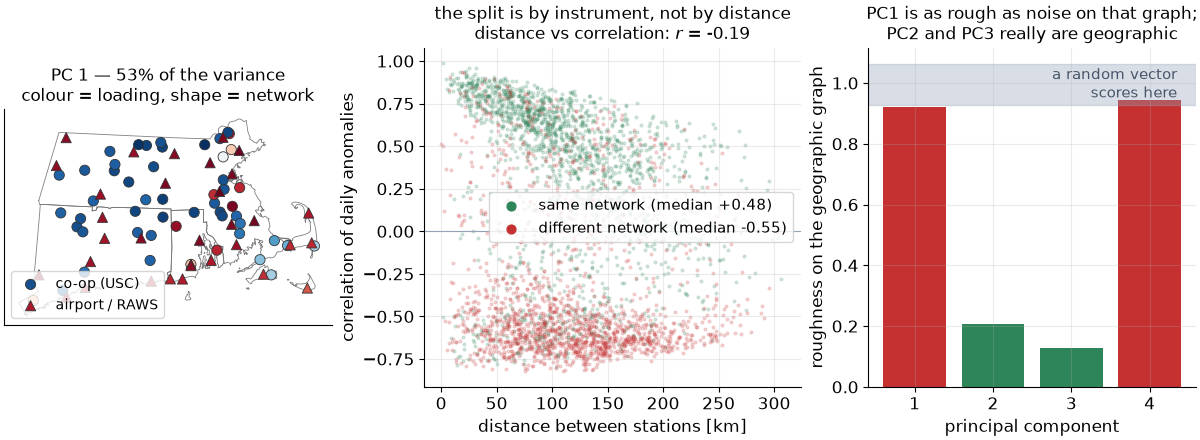

PC1: 52.8% of variance   position+elevation explain R^2 = 0.14   roughness 0.92
PC2: 17.0% of variance   position+elevation explain R^2 = 0.80   roughness 0.21
PC3:  5.0% of variance   position+elevation explain R^2 = 0.75   roughness 0.13

PC1 sign vs network:  airport/RAWS 33/33 positive,  co-op 43/52 negative


In [29]:
R = np.corrcoef(T.Ztrain)
r_edge = T.ei.vec(R)
d_km = np.sqrt(T.D2_edge) / 1000.0

network = np.array([s[:3] for s in T.station_ids])
is_coop = network == "USC"
same_net = is_coop[T.ei.iu[0]] == is_coop[T.ei.iu[1]]

lam_geo, U_geo = np.linalg.eigh(L_geo)
def cum_energy(B):
    c = B.T @ T.Ztest
    return np.cumsum(np.sum(c ** 2, axis=1)) / np.sum(T.Ztest ** 2)
cum_geo = cum_energy(U_geo)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.15, 1]})

ax = axes[0]
T.draw_states(ax)
v = T.Upca[:, 0]
lim = np.abs(v).max()
for m_, mk, lab in [(is_coop, "o", "co-op (USC)"), (~is_coop, "^", "airport / RAWS")]:
    ax.scatter(T.PK[m_, 0], T.PK[m_, 1], c=v[m_], cmap="RdBu_r", vmin=-lim, vmax=lim,
               marker=mk, s=54, edgecolor="0.2", linewidth=0.6, zorder=3, label=lab)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(fontsize=10, loc="lower left")
ax.set_title(f"PC 1 — {100*T.pca_var[0]:.0f}% of the variance\n"
             "colour = loading, shape = network")

ax = axes[1]
for m_, c, lab in [(same_net, "#2f855a", "same network"), (~same_net, "#c53030", "different network")]:
    ax.scatter(d_km[m_], r_edge[m_], s=4, alpha=0.18, color=c)
    ax.scatter([], [], s=40, color=c,
               label=f"{lab} (median {np.median(r_edge[m_]):+.2f})")
ax.axhline(0, color="#94a3b8", lw=0.8)
ax.set_xlabel("distance between stations [km]")
ax.set_ylabel("correlation of daily anomalies")
ax.set_title("the split is by instrument, not by distance\n"
             f"distance vs correlation: $r$ = {np.corrcoef(d_km, r_edge)[0,1]:.2f}")
ax.legend(fontsize=11, loc="center right")

ax = axes[2]
rq = [float(T.Upca[:, k] @ L_geo @ T.Upca[:, k]) for k in range(4)]
rq_rand = np.array([(lambda q: q @ L_geo @ q / (q @ q))(
    np.random.default_rng(i).standard_normal(T.N)) for i in range(200)])
ax.bar(np.arange(1, 5), rq,
       color=["#c53030" if r_ > 0.6 else C_PCA for r_ in rq])
ax.axhspan(rq_rand.mean() - rq_rand.std(), rq_rand.mean() + rq_rand.std(),
           color="#94a3b8", alpha=0.35)
ax.annotate("a random vector\nscores here", (4.35, rq_rand.mean()), fontsize=11,
            color="#475569", va="center", ha="right")
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("principal component")
ax.set_ylabel("roughness on the geographic graph")
ax.set_title("PC1 is as rough as noise on that graph;\nPC2 and PC3 really are geographic")
plt.show()

from numpy.linalg import lstsq
X_geo = np.column_stack([np.ones(T.N), T.PK[:, 0], T.PK[:, 1], T.elev])
for k in range(3):
    b_, *_ = lstsq(X_geo, T.Upca[:, k], rcond=None)
    r2 = 1 - np.sum((T.Upca[:, k] - X_geo @ b_) ** 2) / np.sum(
        (T.Upca[:, k] - T.Upca[:, k].mean()) ** 2)
    print(f"PC{k+1}: {100*T.pca_var[k]:4.1f}% of variance   "
          f"position+elevation explain R^2 = {r2:.2f}   roughness {rq[k]:.2f}")
print(f"\nPC1 sign vs network:  airport/RAWS {int((T.Upca[~is_coop, 0] > 0).sum())}/"
      f"{int((~is_coop).sum())} positive,  co-op {int((T.Upca[is_coop, 0] < 0).sum())}/"
      f"{int(is_coop.sum())} negative")

## 3.4  Learn the graph instead &mdash; Kalofolias (AISTATS 2016)

Stop guessing the edges. Fit them, by asking for the graph on which the observed signals are
**smooth**:

$$\min_{w \ge 0}\;\; \underbrace{2\,z^\top w}_{\substack{\text{pay for edges between}\\ \text{stations that disagree}}}
\;-\;\underbrace{\alpha \sum_i \log(d_i)}_{\substack{\text{no isolated}\\ \text{station}}}
\;+\;\underbrace{\beta \lVert w \rVert^2}_{\substack{\text{spread the weight,}\\ \text{keep it sparse}}}$$

where $z_{ij} = \sum_t (z_{it} - z_{jt})^2$ is how much the two stations' histories disagree.
The first term is $\sum_t z_t^\top L z_t$ written edge-wise &mdash; **it is Dirichlet energy again**,
now minimised over the *graph* instead of over the signal. Convex, 0.07 s.

| | test RMSE [$^\circ$C] |
|---|---|
| geographic graph | 2.475 |
| **learned graph (Kalofolias)** | **1.290** |

**48% better than geography**, on days the graph never saw. Paired per-day difference
$1.03 \pm 0.08\ ^\circ$C &mdash; thirteen standard errors.


## 3.4  What the learned graph discovered

**And we can see exactly what it discovered.** Nobody told it about station networks:

| | share of edge weight joining **same-network** stations |
|---|---|
| chance | 52% |
| geographic graph | 54% &mdash; it never noticed |
| **learned graph** | **90%** |

It found the co-op/airport split from three years of temperatures alone, and it reached up to
266 km to do it (median edge 56 km, against 26 km for the geographic graph). *That* is the
1.2 $^\circ$C.

## 3.4  The learned graph, and what it is worth

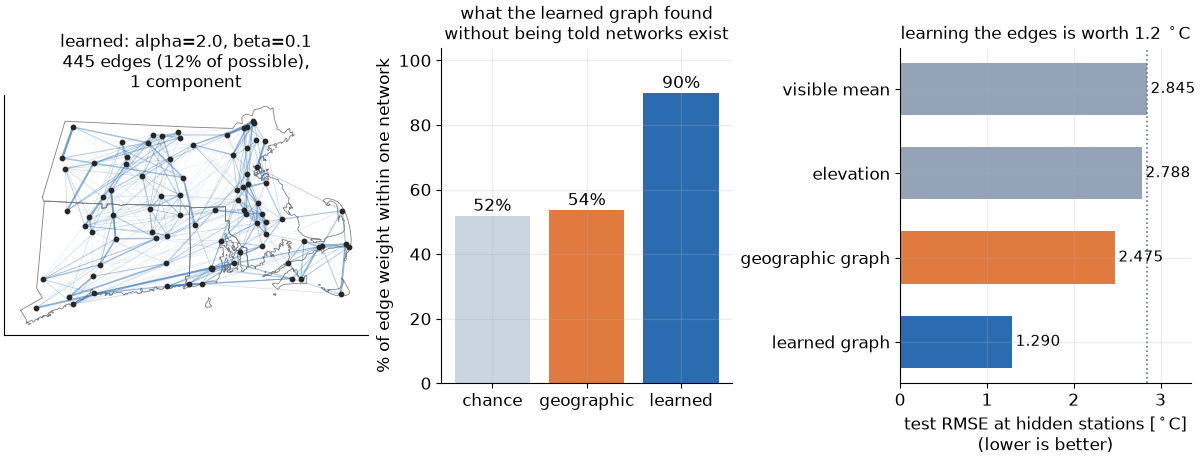

paired per-day difference, geographic - learned: +1.030 +- 0.081 degC
(12.7 standard errors, over 116 test days)
geographic:  301 edges, median length  25.9 km, longest  73.9 km, 54% of weight within one network
learned   :  445 edges, median length  55.5 km, longest 265.9 km, 90% of weight within one network


In [30]:
kalo_best, kalo_rows = T.select_on_validation(T.build_kalofolias())
w_kalo = T.trace_normalised(kalo_best["w"])
L_kalo = T.L_of(w_kalo)
RMSE["learned graph"] = T.eval_graph(kalo_best["w"], T.test_days, T.test_masks,
                                     [kalo_best["gamma"]])[1]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.25, 1, 1]})
graph_on_map(axes[0], w_kalo, f"learned: {kalo_best['label']}", color=C_KALO)

ax = axes[1]
share = [100 * same_net.mean()] + [100 * w[same_net].sum() / w.sum() for w in (w_geo, w_kalo)]
ax.bar(range(3), share, color=["#cbd5e1", C_GEO, C_KALO])
for x_, v_ in enumerate(share):
    ax.text(x_, v_ + 1.5, f"{v_:.0f}%", ha="center", fontsize=12)
ax.set_xticks(range(3))
ax.set_xticklabels(["chance", "geographic", "learned"])
ax.set_ylim(0, 104)
ax.set_ylabel("% of edge weight within one network")
ax.set_title("what the learned graph found\nwithout being told networks exist")

rmse_bars(axes[2], {"visible mean": (RMSE["visible mean"], C_BASE),
                    "elevation": (RMSE["elevation"], C_BASE),
                    "geographic graph": (RMSE["geographic graph"], C_GEO),
                    "learned graph": (RMSE["learned graph"], C_KALO)},
          "learning the edges is worth 1.2 $^\\circ$C")
plt.show()

d_geo = T.per_day_rmse(T.test_days, T.test_masks, w=geo_best["w"], gamma=geo_best["gamma"])
d_kalo = T.per_day_rmse(T.test_days, T.test_masks, w=kalo_best["w"], gamma=kalo_best["gamma"])
m, se, z = T.paired(d_geo, d_kalo)
print(f"paired per-day difference, geographic - learned: {m:+.3f} +- {se:.3f} degC\n"
      f"({z:.1f} standard errors, over {len(d_geo)} test days)")
for nm, w in [("geographic", w_geo), ("learned   ", w_kalo)]:
    a = w > 1e-8 * w.max()
    print(f"{nm}: {int(a.sum()):4d} edges, median length {np.median(d_km[a]):5.1f} km, "
          f"longest {d_km[a].max():5.1f} km, {100*w[same_net].sum()/w.sum():.0f}% of weight "
          f"within one network")

## 3.5  Now the uncomfortable comparison: PCA

The learned graph beat geography. But the fair question is not *did the graph beat geography* &mdash;
it is **did the graph beat the simplest thing that also uses the training data.**

**PCA** on the same 439 training days. Take the top $K$ principal components, fit their scores to the
68 visible stations by least squares, read off the 17 hidden ones. $K = 8$, chosen on validation.
No graph. No edges. No Laplacian.

| | test RMSE [$^\circ$C] |
|---|---|
| learned graph (Kalofolias) | 1.290 |
| **PCA, $K=8$** | **1.238** |

PCA wins, by $0.061 \pm 0.019\ ^\circ$C &mdash; small, but 3.3 standard errors, so it is real.

> The gain came from **using the observations**, not from expressing them as a graph.
> Everything the Laplacian added &mdash; locality, named edges, a frequency axis &mdash; bought
> no accuracy on this task.

## 3.5  PCA against the learned graph, day by day

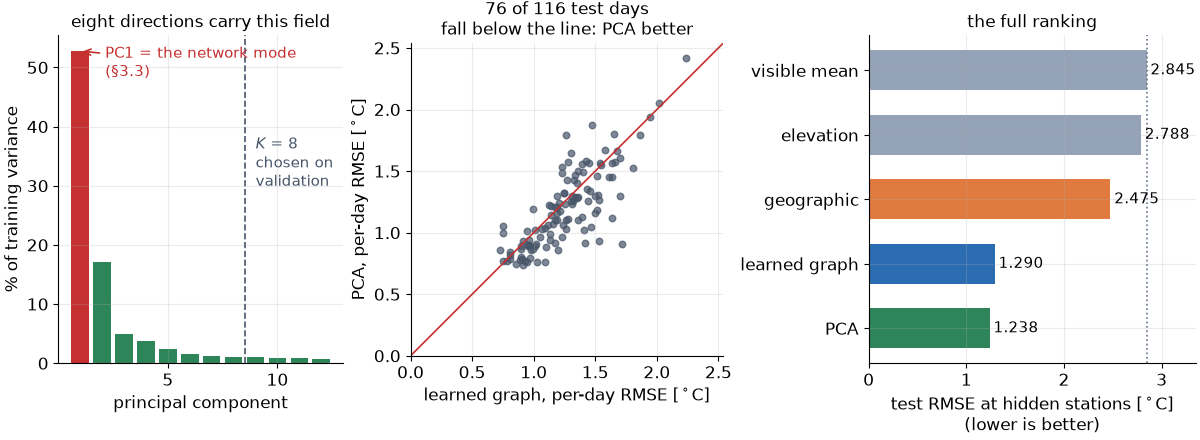

paired per-day difference, learned graph - PCA: +0.061 +- 0.019 degC
(3.3 standard errors) -> PCA is genuinely, slightly better


In [31]:
PCA_K = min(T.PCA_GRID, key=lambda k: T.eval_baseline("pca", T.val_days, T.val_masks, k))
RMSE["PCA"] = T.eval_baseline("pca", T.test_days, T.test_masks, PCA_K)
d_pca = T.per_day_rmse(T.test_days, T.test_masks, kind="pca", n_comp=PCA_K)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.1, 1.15]})

ax = axes[0]
nshow = 12
ax.bar(np.arange(1, nshow + 1), 100 * T.pca_var[:nshow],
       color=["#c53030"] + [C_PCA] * (nshow - 1))
ax.axvline(PCA_K + 0.5, color="#475569", ls="--", lw=1.2)
ax.annotate(f"$K$ = {PCA_K}\nchosen on\nvalidation", (PCA_K + 0.5, 30),
            xytext=(8, 0), textcoords="offset points", fontsize=11, color="#475569")
ax.annotate("PC1 = the network mode\n(§3.3)", (1, 100 * T.pca_var[0]),
            xytext=(18, -18), textcoords="offset points", fontsize=11, color="#c53030",
            arrowprops=dict(arrowstyle="->", color="#c53030", lw=1.2))
ax.set_xlabel("principal component")
ax.set_ylabel("% of training variance")
ax.set_title("eight directions carry this field")

ax = axes[1]
lim = max(d_kalo.max(), d_pca.max()) * 1.05
ax.scatter(d_kalo, d_pca, s=22, color="#475569", alpha=0.7)
ax.plot([0, lim], [0, lim], color="#c53030", lw=1.2)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("learned graph, per-day RMSE [$^\\circ$C]")
ax.set_ylabel("PCA, per-day RMSE [$^\\circ$C]")
ax.set_title(f"{int((d_pca < d_kalo).sum())} of {len(d_pca)} test days\n"
             "fall below the line: PCA better")

rmse_bars(axes[2], {"visible mean": (RMSE["visible mean"], C_BASE),
                    "elevation": (RMSE["elevation"], C_BASE),
                    "geographic": (RMSE["geographic graph"], C_GEO),
                    "learned graph": (RMSE["learned graph"], C_KALO),
                    "PCA": (RMSE["PCA"], C_PCA)},
          "the full ranking")
plt.show()

m, se, z = T.paired(d_kalo, d_pca)
print(f"paired per-day difference, learned graph - PCA: {m:+.3f} +- {se:.3f} degC\n"
      f"({z:.1f} standard errors) -> PCA is genuinely, slightly better")

## 3.6  PCA *is* this analysis, with the constraints taken off

Both methods start from **the same matrix**: the Gram matrix $ZZ^\top$ of the training anomalies.
Kalofolias only ever sees the data through $z_{ij} = \lVert z_i - z_j \rVert^2$, which is built
from $ZZ^\top$ and nothing else.

| | **PCA** | **Graph** |
|---|---|---|
| What is diagonalised | covariance $C \propto ZZ^\top$ | Laplacian $L = D - W$ |
| Constraints on it | symmetric, PSD. **That is all.** | symmetric, PSD, **and** $L\mathbf{1}=\mathbf{0}$, off-diagonals $\le 0$, sparse |
| Basis ordered by | variance explained, high first | roughness $\lambda_k$, smooth first |
| What you get to say | "these directions vary most" | "**these two stations** are coupled, by this much" |

So the graph is **PCA with a structural prior bolted on**. Two consequences, both measurable:

1. **The shared part is genuinely shared.** The first five PCA directions and the five smoothest
   learned graph modes are nearly the same subspace (cosines $0.997, 0.97, 0.93, 0.90, 0.83$).
   They then diverge. The leading structure is not a graph phenomenon or a PCA phenomenon &mdash;
   it is in the data.
2. **A constraint that is false costs you.** Every Laplacian is forced to have the constant vector
   as $u_1$ with $\lambda_1=0$. But the anomalies were built by subtracting the daily mean, so
   they carry **exactly zero** energy in that direction. One of the graph's eight cheapest modes
   is spent on a direction the signal can never occupy. PCA has no such obligation.

Constraints can only make the training fit worse. They earn their place only when they are *true*.

## 3.6  Shared subspace, and a mode the signal cannot use

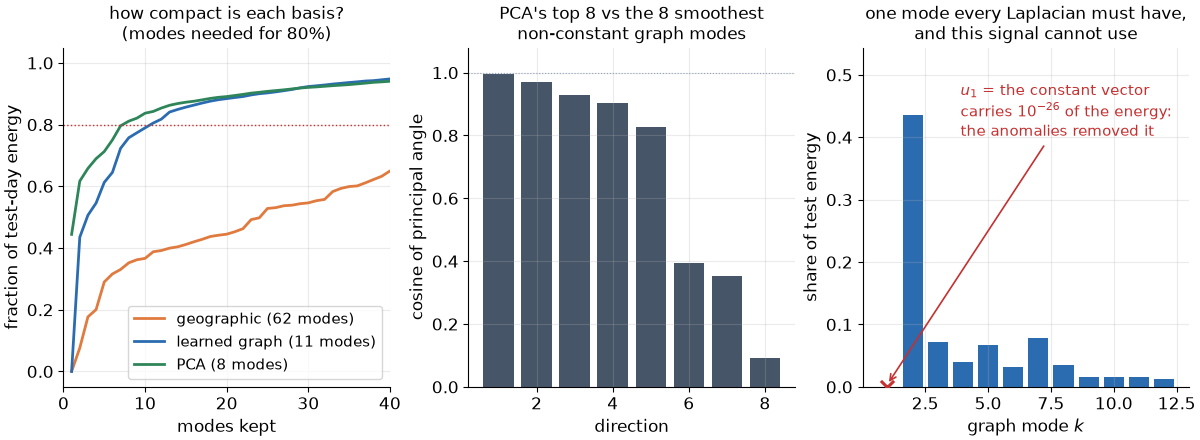

cos angle(u_1, constant vector) = 1.0000
test-anomaly energy along the constant = 8.0e-26 of 7.8e+04
principal-angle cosines: [0.997 0.969 0.93  0.902 0.828 0.394 0.354 0.093]


In [32]:
lam_k, U_kalo = np.linalg.eigh(L_kalo)
cum_kalo, cum_pca = cum_energy(U_kalo), cum_energy(T.Upca)
k80s = {n: int(np.searchsorted(c, 0.80) + 1)
        for n, c in [("geographic", cum_geo), ("learned graph", cum_kalo), ("PCA", cum_pca)]}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.4))

ax = axes[0]
for c, col, lab in [(cum_geo, C_GEO, "geographic"), (cum_kalo, C_KALO, "learned graph"),
                    (cum_pca, C_PCA, "PCA")]:
    ax.plot(np.arange(1, T.N + 1), c, lw=2, color=col, label=f"{lab} ({k80s[lab]} modes)")
ax.axhline(0.8, color="#c53030", lw=1, ls=":")
ax.set_xlim(0, 40)
ax.set_xlabel("modes kept")
ax.set_ylabel("fraction of test-day energy")
ax.set_title("how compact is each basis?\n(modes needed for 80%)")
ax.legend(fontsize=11, loc="lower right")

ax = axes[1]
sv = np.linalg.svd(T.Upca[:, :PCA_K].T @ U_kalo[:, 1:PCA_K + 1], compute_uv=False)
ax.bar(np.arange(1, PCA_K + 1), sv, color="#475569")
ax.axhline(1, color="#94a3b8", lw=0.8, ls=":")
ax.set_ylim(0, 1.08)
ax.set_xlabel("direction")
ax.set_ylabel("cosine of principal angle")
ax.set_title(f"PCA's top {PCA_K} vs the {PCA_K} smoothest\nnon-constant graph modes")

ax = axes[2]
one = np.ones(T.N) / np.sqrt(T.N)
share = np.array([np.sum((U_kalo[:, k] @ T.Ztest) ** 2) for k in range(T.N)])
share /= share.sum()
ax.bar(np.arange(1, 13), share[:12], color=C_KALO)
ax.scatter([1], [0], marker="x", s=90, color="#c53030", lw=2.2, zorder=5)
ax.annotate("$u_1$ = the constant vector\ncarries $10^{-26}$ of the energy:\n"
            "the anomalies removed it",
            xy=(1, 0.004), xytext=(0.30, 0.74), textcoords="axes fraction",
            fontsize=11, color="#c53030",
            arrowprops=dict(arrowstyle="->", color="#c53030", lw=1.2))
ax.set_ylim(0, share[:12].max() * 1.25)
ax.set_xlabel("graph mode $k$")
ax.set_ylabel("share of test energy")
ax.set_title("one mode every Laplacian must have,\nand this signal cannot use")
plt.show()

print(f"cos angle(u_1, constant vector) = {abs(one @ U_kalo[:, 0]):.4f}\n"
      f"test-anomaly energy along the constant = {np.sum((one @ T.Ztest)**2):.1e} "
      f"of {np.sum(T.Ztest**2):.1e}")
print("principal-angle cosines:", np.round(sv, 3))

## 3.7  So when *does* the graph earn its keep?

The constraints are a **regulariser**. A regulariser is worth having exactly when you do not have
enough data to do without one. So shrink the training set and watch.

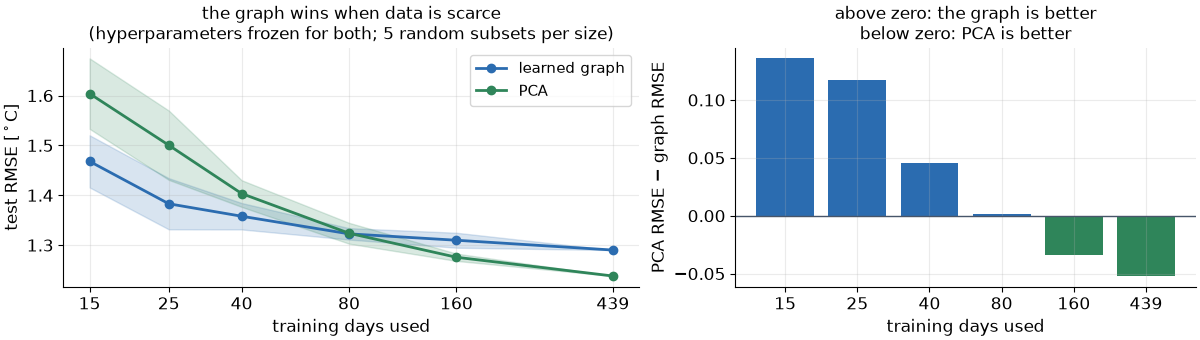

    15 training days:  graph 1.468   PCA 1.604   -> graph
    25 training days:  graph 1.383   PCA 1.500   -> graph
    40 training days:  graph 1.358   PCA 1.403   -> graph
    80 training days:  graph 1.323   PCA 1.324   -> graph
   160 training days:  graph 1.310   PCA 1.276   -> PCA
   439 training days:  graph 1.290   PCA 1.238   -> PCA


In [33]:
curve = T.sample_size_curve([15, 25, 40, 80, 160, len(T.train_days)], reps=5)
sz = np.array(curve["sizes"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
for key, col, lab in [("graph", C_KALO, "learned graph"), ("pca", C_PCA, "PCA")]:
    m_ = np.array(curve[key]); s_ = np.array(curve[key + "_sd"])
    ax.plot(sz, m_, "o-", color=col, lw=2, label=lab)
    ax.fill_between(sz, m_ - s_, m_ + s_, color=col, alpha=0.18)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks(sz); ax.set_xticklabels(sz)
ax.set_xlabel("training days used")
ax.set_ylabel("test RMSE [$^\\circ$C]")
ax.set_title("the graph wins when data is scarce\n(hyperparameters frozen for both; "
             "5 random subsets per size)")
ax.legend(fontsize=11)

ax = axes[1]
diff = np.array(curve["pca"]) - np.array(curve["graph"])
ax.bar(np.arange(len(sz)), diff, color=[C_KALO if d > 0 else C_PCA for d in diff])
ax.axhline(0, color="#475569", lw=1)
ax.set_xticks(np.arange(len(sz))); ax.set_xticklabels(sz)
ax.set_xlabel("training days used")
ax.set_ylabel("PCA RMSE $-$ graph RMSE")
ax.set_title("above zero: the graph is better\nbelow zero: PCA is better")
plt.show()

for s_, g_, p_ in zip(sz, curve["graph"], curve["pca"]):
    tag = "graph" if g_ < p_ else "PCA"
    print(f"  {s_:4d} training days:  graph {g_:.3f}   PCA {p_:.3f}   -> {tag}")

## Part 3 &mdash; conclusions

| | test RMSE [$^\circ$C] | vs doing nothing |
|---|---|---|
| predict the visible mean | 2.845 | &mdash; |
| elevation regression | 2.788 | $-2\%$ |
| **graph from geography** | 2.475 | $-13\%$ |
| **graph learned from data** | 1.290 | $-55\%$ |
| **PCA, no graph** | **1.238** | $-56\%$ |

1. **Where the edges come from matters far more than that you used a graph.** Geography to learned
   edges was worth $1.2\,^\circ$C. That is the whole result.
2. **Check what the dominant mode actually is before you choose an operator.** Here it was the
   co-op/airport instrument split &mdash; 53% of the variance, no spatial structure at all. A
   basis built to be spatially smooth is structurally incapable of representing it, and the
   spectral analysis told us so before any tuning.
3. **Report against the right baseline.** Against geography, the learned graph is a triumph.
   Against PCA &mdash; the simplest thing that also learns from the data &mdash; it loses.
   Which comparison you publish determines what people believe.
4. **The graph's constraints are a prior, and priors are not free.** With 439 days they cost
   accuracy. Below roughly 100 days they pay for themselves.
5. **Accuracy is not the only currency.** PCA gives you eight directions. The graph gives you
   445 named edges between real stations, a locality structure, and a frequency axis &mdash; and
   it extends to a new station without refitting. If you need to *explain*, or to add nodes,
   that is worth a small amount of RMSE. If you only need the numbers, it is not.


## Part 3 &mdash; what this does not show

One region, one variable, one task, reconstruction rather than
forecasting, and a single graph-learning method. Nothing here says graphs lose in general &mdash;
it says they lost *here*, and it shows you how to check on your own problem.